# **LINEART RESTORATION (CLOSER) V12**






# ***DATA***

In [1]:
# CODE BLOCK 1 (IMPORT DATASET)

# =============================================================================
# CODE BLOCK 0 (LOAD DATASET)
# Brings the zip from the generator notebook into /content, unzips it, and
# restores every variable blocks 4 / 4b / 5 expect (paths, file lists,
# IMAGE_SIZE, CORRUPTION_KWARGS) from split.json.
# =============================================================================
import os, json, shutil, glob, time, subprocess

#UPLOAD_MODE = "upload"     # "drive" (recommended for multi-GB zips) or "upload" (browser upload)
UPLOAD_MODE = "drive"     # "drive" (recommended for multi-GB zips) or "upload" (browser upload)
LOCAL_ZIP   = "/content/inkrepair_dataset.zip"
split_root  = "/content/split"

# ---- 1. get the zip onto the local Colab disk ------------------------------
t0 = time.perf_counter()
if UPLOAD_MODE == "drive":
    import gdown
    gdown.download("https://drive.google.com/file/d/1NO8i_J5mSlh7YYuwh2ZyFqkIW7ISrGuk/view?usp=drive_link", LOCAL_ZIP, quiet=False, fuzzy=True)
else:
    from google.colab import files
    uploaded = files.upload()                      # pick the zip in the file dialog
    assert uploaded, "Nothing uploaded"
    name = next(iter(uploaded))
    src = os.path.abspath(name)                    # files.upload saves to the cwd
    if src != LOCAL_ZIP:
        os.replace(src, LOCAL_ZIP)

print(f"zip ready: {os.path.getsize(LOCAL_ZIP) / 1e9:.2f} GB "
      f"in {time.perf_counter() - t0:.0f} s")

# ---- 2. unzip and locate the split folder (whatever the zip's top folder is) --
tmp_dir = "/content/_unzip"
shutil.rmtree(tmp_dir, ignore_errors=True)
shutil.rmtree(split_root, ignore_errors=True)
t0 = time.perf_counter()
subprocess.run(["unzip", "-q", LOCAL_ZIP, "-d", tmp_dir], check=True)

found = glob.glob(os.path.join(tmp_dir, "**", "split.json"), recursive=True)
assert found, "split.json not found in the zip. Was it built by CODE BLOCK 3?"
shutil.move(os.path.dirname(found[0]), split_root)
shutil.rmtree(tmp_dir, ignore_errors=True)
os.remove(LOCAL_ZIP)                               # free disk space
print(f"unzipped in {time.perf_counter() - t0:.0f} s -> {split_root}")

# ---- 3. restore the split manifest ------------------------------------------
with open(os.path.join(split_root, "split.json")) as fh:
    manifest = json.load(fh)

IMAGE_SIZE        = manifest["image_size"]
#CORRUPTION_KWARGS = manifest["corruption"]         # tuples come back as lists; harmless
train_files       = manifest["train"]
test_files        = manifest["test"]
sample_files      = manifest["sample"]

test_clean_dir = os.path.join(split_root, "clean_test")
test_corr_dir  = os.path.join(split_root, "corrupted_test")
pre_root       = os.path.join(split_root, "precorrupted")
pre_clean      = os.path.join(pre_root, "clean")
pre_corr       = os.path.join(pre_root, "corrupted")

# clean_training/ held symlinks and was excluded from the zip. The same images,
# already resized to IMAGE_SIZE, are in precorrupted/clean, so use that folder.
train_dir = pre_clean

# ---- 4. sanity checks ---------------------------------------------------------
for d in (test_clean_dir, test_corr_dir, pre_clean, pre_corr):
    assert os.path.isdir(d), f"Missing folder: {d}"

n_test_clean = len(os.listdir(test_clean_dir))
n_test_corr  = len(os.listdir(test_corr_dir))
assert n_test_clean == n_test_corr == len(test_files), \
    f"test pairs mismatch: {n_test_clean} clean / {n_test_corr} corrupted / {len(test_files)} listed"
assert all(os.path.exists(os.path.join(test_clean_dir, f)) for f in sample_files), \
    "preview files missing from clean_test"

pre_manifest_path = os.path.join(pre_root, "manifest.json")
if os.path.exists(pre_manifest_path):
    with open(pre_manifest_path) as fh:
        pm = json.load(fh)
    if not pm.get("complete", False):
        print("WARNING: pre-corrupted generation was not marked complete")
    print(f"pre-corrupted: {pm.get('n_variants')} variants/image (as configured)")

n_pre_clean = len([f for f in os.listdir(pre_clean) if f.endswith(".png")])
n_pre_corr  = len([f for f in os.listdir(pre_corr)
                   if f.endswith(".png") and not f.endswith(".tmp.png")])
print(f"IMAGE_SIZE {IMAGE_SIZE} | train {len(train_files)} "
      f"(pre-clean {n_pre_clean}, pre-corrupted pairs {n_pre_corr}) | "
      f"test {len(test_files)} | sample {sample_files}")
if n_pre_clean < len(train_files):
    print(f"WARNING: {len(train_files) - n_pre_clean} training images missing from precorrupted/clean")


Downloading...
From (original): https://drive.google.com/uc?id=1NO8i_J5mSlh7YYuwh2ZyFqkIW7ISrGuk
From (redirected): https://drive.google.com/uc?id=1NO8i_J5mSlh7YYuwh2ZyFqkIW7ISrGuk&confirm=t&uuid=824481a9-7087-4df8-906b-3f6da4829b29
To: /content/inkrepair_dataset.zip
100%|██████████| 1.15G/1.15G [00:29<00:00, 39.3MB/s]


zip ready: 1.15 GB in 32 s
unzipped in 13 s -> /content/split
pre-corrupted: 6 variants/image (as configured)
IMAGE_SIZE 896 | train 9000 (pre-clean 9000, pre-corrupted pairs 54000) | test 1000 | sample ['pair_00000.png', 'pair_00001.png', 'pair_00002.png', 'pair_00003.png']


# ***DATA LOADER (split)***

In [ ]:
# ORDER MATTERS: corrupt the CRISP image, then augment the pair together.
# Augmenting first leaves hard-white holes over blurred strokes, so every
# hole pixel passes _hole_mask's (corrupted > 0.9) test instead of being
# softened below it -> 3x hole weight applies to far more pixels -> the
# model over-predicts ink and lines come out thick.

In [2]:
# =============================================================================
# CODE BLOCK 4 (DATA LOADERS: pre-corrupted train + frozen test)
# Training pairs come from disk only (no on-the-fly corruption).
# Each epoch shows every training image once with a random stored variant,
# then applies the same paired augmentation to both images.
# =============================================================================
import os, torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms


class PrecorruptedPairDataset(Dataset):
    """Training set: pairs read from disk (random variant per load) + paired augmentation."""
    def __init__(self, clean_dir, corrupted_dir, files, image_size=IMAGE_SIZE, augment=True):
        self.clean_dir     = clean_dir
        self.corrupted_dir = corrupted_dir
        self.image_size    = image_size
        self.augment       = augment

        variants = {}
        for f in os.listdir(corrupted_dir):
            if f.endswith(".png") and not f.endswith(".tmp.png") and "_v" in f:
                variants.setdefault(f.rsplit("_v", 1)[0], []).append(f)

        stems = sorted(os.path.splitext(f)[0] for f in files)
        self.items = [(s, sorted(variants[s])) for s in stems
                      if s in variants
                      and os.path.exists(os.path.join(clean_dir, s + ".png"))]
        self.files = [s + ".png" for s, _ in self.items]

        n_var = [len(v) for _, v in self.items]
        print(f"[precorrupted] {len(self.items)} images, "
              f"{sum(n_var)} pairs ({min(n_var, default=0)}-{max(n_var, default=0)} variants/image)")
        if len(self.items) < len(stems):
            print(f"  WARNING: {len(stems) - len(self.items)} training images have no "
                  f"pre-corrupted pairs (generation incomplete?) and are skipped")

        self.to_tensor = transforms.ToTensor()
        # fill=1.0 = white on [0, 1] tensors
        self.augmentation = transforms.Compose([
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.2),
            transforms.RandomRotation(
                degrees=10,
                interpolation=transforms.InterpolationMode.BILINEAR,
                fill=1.0),
            transforms.RandomAffine(
                degrees=0, translate=(0.05, 0.05), scale=(0.95, 1.05),
                interpolation=transforms.InterpolationMode.BILINEAR,
                fill=1.0),
        ])

    def __len__(self):
        return len(self.items)

    def __getitem__(self, idx):
        stem, vs = self.items[idx]
        v = vs[int(torch.randint(len(vs), (1,)))]     # torch RNG is seeded per worker
        clean = Image.open(os.path.join(self.clean_dir, stem + ".png")).convert("L")
        corr  = Image.open(os.path.join(self.corrupted_dir, v)).convert("L")
        assert clean.size == corr.size == (self.image_size, self.image_size), \
            f"{v}: expected {self.image_size}², got {clean.size} / {corr.size}"

        corrupted, clean = self.to_tensor(corr), self.to_tensor(clean)
        if self.augment:
            # one call on a 2-channel stack -> identical geometry for both images
            pair = self.augmentation(torch.cat([corrupted, clean], dim=0))
            corrupted, clean = pair[0:1], pair[1:2]
        return corrupted, clean


class FrozenPairDataset(Dataset):
    """Test set: pairs read straight from disk. No augmentation, no RNG, no surprises."""
    def __init__(self, clean_dir, corrupted_dir, files=None, image_size=IMAGE_SIZE):
        self.clean_dir     = clean_dir
        self.corrupted_dir = corrupted_dir
        self.files = sorted(files) if files is not None else sorted(
            f for f in os.listdir(clean_dir) if f.lower().endswith(".png"))
        missing = [f for f in self.files
                   if not os.path.exists(os.path.join(corrupted_dir, f))]
        assert not missing, f"Missing corrupted counterparts: {missing[:5]}"
        self.to_tensor  = transforms.ToTensor()
        self.image_size = image_size
        print(f"[frozen] {len(self.files)} pairs in {clean_dir}")

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        f = self.files[idx]
        clean = Image.open(os.path.join(self.clean_dir, f)).convert("L")
        corr  = Image.open(os.path.join(self.corrupted_dir, f)).convert("L")
        assert clean.size == corr.size == (self.image_size, self.image_size), \
            f"{f}: expected {self.image_size}², got {clean.size} / {corr.size}"
        return self.to_tensor(corr), self.to_tensor(clean), f


# ---- datasets ----------------------------------------------------------------
pre_dataset    = PrecorruptedPairDataset(pre_clean, pre_corr, train_files)
train_dataset  = pre_dataset                     # alias used by CODE BLOCK 5
test_dataset   = FrozenPairDataset(test_clean_dir, test_corr_dir)
sample_dataset = FrozenPairDataset(test_clean_dir, test_corr_dir, files=sample_files)

# ---- loaders -----------------------------------------------------------------
train_loader = DataLoader(pre_dataset, batch_size=4, shuffle=True,
                          num_workers=min(4, os.cpu_count()), pin_memory=True,
                          persistent_workers=True, drop_last=False)
test_loader  = DataLoader(test_dataset, batch_size=4, shuffle=False,
                          num_workers=2, pin_memory=True)
print("train_loader:", len(train_loader), "batches/epoch")

# ---- the 4 fixed preview images, loaded once as tensors ------------------------
ex_corrupted  = torch.stack([sample_dataset[i][0] for i in range(len(sample_dataset))])
ex_clean      = torch.stack([sample_dataset[i][1] for i in range(len(sample_dataset))])
EXAMPLE_FILES = sample_dataset.files
print("Preview tensors:", ex_corrupted.shape)

[precorrupted] 9000 images, 54000 pairs (6-6 variants/image)
[frozen] 1000 pairs in /content/split/clean_test
[frozen] 4 pairs in /content/split/clean_test
train_loader: 2250 batches/epoch
Preview tensors: torch.Size([4, 1, 896, 896])


train  :  9000 images
test   :  1000 pairs
sample :     4 pairs -> ['pair_00000.png', 'pair_00001.png', 'pair_00002.png', 'pair_00003.png']
train/test overlap: 0
sample inside test: True

[train] corrupted: (4, 1, 896, 896) torch.float32
[train] clean    : (4, 1, 896, 896) torch.float32
[test ] corrupted: (4, 1, 896, 896) | files: ['pair_00000.png', 'pair_00001.png', 'pair_00002.png', 'pair_00003.png']

train clean          min=0.000 max=1.000 mean=0.923 std=0.254 ink_frac=0.0767
train corrupted      min=0.000 max=1.000 mean=0.924 std=0.251 ink_frac=0.0753
test clean           min=0.000 max=1.000 mean=0.848 std=0.359 ink_frac=0.1517
test corrupted       min=0.000 max=1.000 mean=0.857 std=0.351 ink_frac=0.1435

clean unique values: 256 (first 20) -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

[train] pixels darker in corrupted than clean: 0.000000
[test ] pixels darker in corrupted than clean: 0.000000
[train] hole_frac per image: ['0.0013', '0.0024', '0.0039

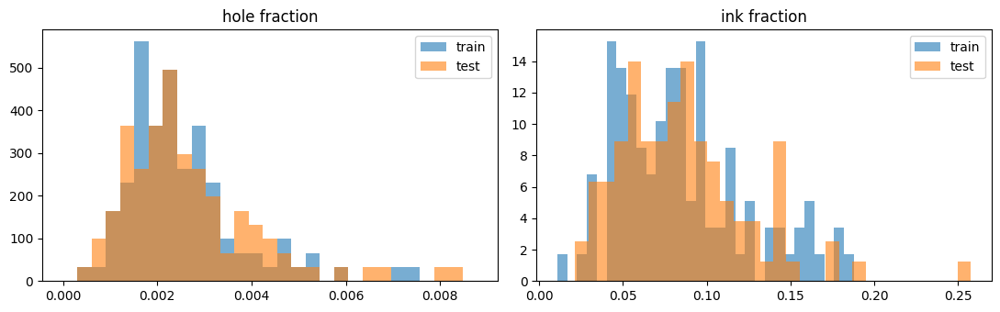

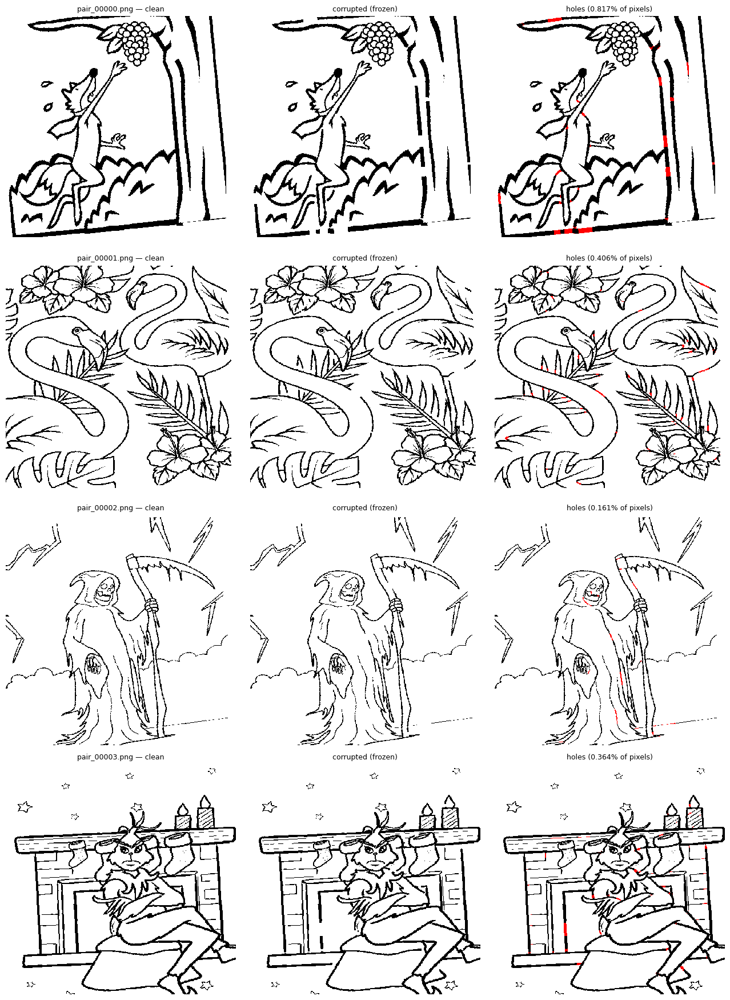

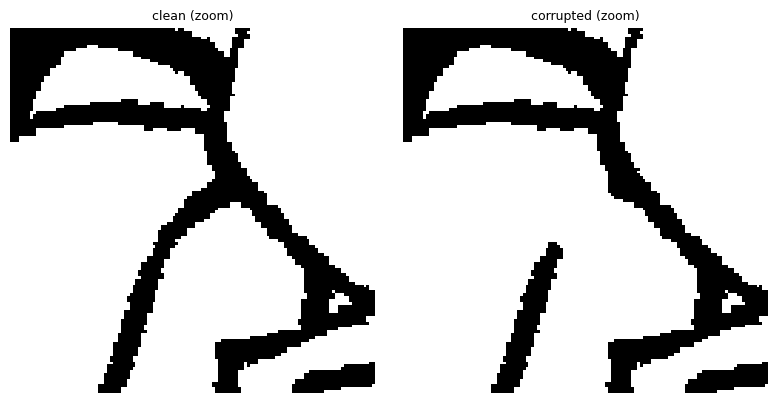

In [3]:
# CODE BLOCK 5 (CHECK DATA LOADERS)

import torch
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 0. SPLIT INTEGRITY
# ---------------------------------------------------------
print(f"train  : {len(train_dataset):5d} images")
print(f"test   : {len(test_dataset):5d} pairs")
print(f"sample : {len(sample_dataset):5d} pairs -> {EXAMPLE_FILES}")

train_names = set(train_dataset.files)
test_names  = set(test_dataset.files)
print("train/test overlap:", len(train_names & test_names))     # must be 0
print("sample inside test:", set(sample_dataset.files) <= test_names)

# ---------------------------------------------------------
# 1. SHAPES / DTYPES / RANGE
# ---------------------------------------------------------
corrupted_batch, clean_batch = next(iter(train_loader))
print("\n[train] corrupted:", tuple(corrupted_batch.shape), corrupted_batch.dtype)
print("[train] clean    :", tuple(clean_batch.shape), clean_batch.dtype)

t_corr, t_clean, t_names = next(iter(test_loader))
print("[test ] corrupted:", tuple(t_corr.shape), "| files:", list(t_names))

assert corrupted_batch.shape[1] == 1, "Expected 1 channel"
assert corrupted_batch.shape[-2:] == (IMAGE_SIZE, IMAGE_SIZE)
assert corrupted_batch.shape == clean_batch.shape
assert 0.0 <= corrupted_batch.min() and corrupted_batch.max() <= 1.0

def print_stats(name, img):
    print(f"{name:20s} min={img.min():.3f} max={img.max():.3f} "
          f"mean={img.mean():.3f} std={img.std():.3f} "
          f"ink_frac={(img < 0.5).float().mean():.4f}")

print()
print_stats("train clean",     clean_batch[0])
print_stats("train corrupted", corrupted_batch[0])
print_stats("test clean",      t_clean[0])
print_stats("test corrupted",  t_corr[0])

# Anti-aliased greys should be present (you binarize only at inference)
u = torch.unique((clean_batch[0] * 255).round().int())
print(f"\nclean unique values: {len(u)} (first 20) -> {u[:20].tolist()}")

# ---------------------------------------------------------
# 2. PAIR CONSISTENCY
# Corruption only paints WHITE over ink -> corrupted >= clean everywhere.
# A violation means the pair is misaligned (e.g. augmentation applied twice).
# ---------------------------------------------------------
def pair_violations(corr, clean, tol=1/255):
    return (corr < clean - tol).float().mean().item()

print(f"\n[train] pixels darker in corrupted than clean: {pair_violations(corrupted_batch, clean_batch):.6f}")
print(f"[test ] pixels darker in corrupted than clean: {pair_violations(t_corr, t_clean):.6f}")

def hole_frac(corr, clean):
    """Same definition as LineLoss._hole_mask: erased = white in input, ink in target."""
    return ((corr > 0.9) & (clean < 0.5)).float().mean(dim=(1, 2, 3))

print("[train] hole_frac per image:", [f"{v:.4f}" for v in hole_frac(corrupted_batch, clean_batch)])
print("[test ] hole_frac per image:", [f"{v:.4f}" for v in hole_frac(t_corr, t_clean)])

# ---------------------------------------------------------
# 3. TRAIN vs TEST DISTRIBUTION
# If these diverge, the frozen test set is not reproducing the training
# corruption and every test metric you compute will be biased.
# ---------------------------------------------------------
@torch.no_grad()
def collect(loader, n_batches):
    holes, inks = [], []
    for k, batch in enumerate(loader):
        corr, clean = batch[0], batch[1]
        holes.append(hole_frac(corr, clean))
        inks.append((clean < 0.5).float().mean(dim=(1, 2, 3)))
        if k + 1 >= n_batches:
            break
    return torch.cat(holes).numpy(), torch.cat(inks).numpy()

train_holes, train_ink = collect(train_loader, 25)
test_holes,  test_ink  = collect(test_loader, 25)

print(f"\nhole_frac  train {train_holes.mean():.4f} ± {train_holes.std():.4f}"
      f"   |   test {test_holes.mean():.4f} ± {test_holes.std():.4f}")
print(f"ink_frac   train {train_ink.mean():.4f} ± {train_ink.std():.4f}"
      f"   |   test {test_ink.mean():.4f} ± {test_ink.std():.4f}")
print(f"empty-hole images in train sample: {(train_holes < 1e-6).sum()} / {len(train_holes)}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
bins = np.linspace(0, max(train_holes.max(), test_holes.max()) * 1.05, 30)
ax[0].hist(train_holes, bins=bins, alpha=.6, label="train", density=True)
ax[0].hist(test_holes,  bins=bins, alpha=.6, label="test",  density=True)
ax[0].set_title("hole fraction"); ax[0].legend()
ax[1].hist(train_ink, bins=30, alpha=.6, label="train", density=True)
ax[1].hist(test_ink,  bins=30, alpha=.6, label="test",  density=True)
ax[1].set_title("ink fraction"); ax[1].legend()
plt.tight_layout(); plt.show()

# ---------------------------------------------------------
# 4. VISUAL CHECK — the 4 fixed preview images
# ---------------------------------------------------------
def show_gray(ax, tensor, title):
    ax.imshow(tensor[0].numpy(), cmap="gray", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(title, fontsize=9); ax.axis("off")

n = len(sample_dataset)
fig, axes = plt.subplots(n, 3, figsize=(13, 4.4 * n))
for r in range(n):
    corr, clean = ex_corrupted[r], ex_clean[r]
    holes = ((corr > 0.9) & (clean < 0.5)).float()
    show_gray(axes[r, 0], clean, f"{EXAMPLE_FILES[r]} — clean")
    show_gray(axes[r, 1], corr,  "corrupted (frozen)")
    ov = np.repeat(clean[0].numpy()[..., None], 3, axis=2)
    ov[holes[0].numpy() > 0] = (1.0, 0.0, 0.0)          # red = erased ink
    axes[r, 2].imshow(ov, interpolation="nearest")
    axes[r, 2].set_title(f"holes ({holes.mean():.3%} of pixels)", fontsize=9)
    axes[r, 2].axis("off")
plt.tight_layout(); plt.show()

# Zoom on one hole region so you can see the anti-aliased edges
corr, clean = ex_corrupted[0], ex_clean[0]
ys, xs = torch.nonzero(((corr > 0.9) & (clean < 0.5))[0], as_tuple=True)
if len(ys):
    cy, cx = int(ys[len(ys)//2]), int(xs[len(xs)//2])
    y0, x0 = max(0, cy - 64), max(0, cx - 64)
    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    show_gray(ax[0], clean[:, y0:y0+128, x0:x0+128], "clean (zoom)")
    show_gray(ax[1], corr[:,  y0:y0+128, x0:x0+128], "corrupted (zoom)")
    plt.tight_layout(); plt.show()

# **MODEL**

- 1 channel binarized input/output
- Resolution: 896x896
- Workded with small holes (a previous dataset) but struggles with bigger ones
- UNet + Attention
-  WARNING: The weight of the masked loss is important.
  - Too high: holes filled but bad the rest
  - Too low: holes not filled





In [ ]:
#CODE BLOCK 6 (MODEL/Sinusoidal embedding)

import torch
import torch.nn as nn
class SinusoidalPosEmbed2D(nn.Module):
    def __init__(self, dim, h, w):
        super().__init__()
        assert dim % 4 == 0, "dim must be divisible by 4"
        pe_h = self._make_pe(h, dim // 2)   # (H, dim/2)
        pe_w = self._make_pe(w, dim // 2)   # (W, dim/2)
        pe = torch.cat([pe_h.unsqueeze(1).expand(-1, w, -1),
                        pe_w.unsqueeze(0).expand(h, -1, -1)], dim=-1)  # (H, W, dim)
        self.register_buffer('pe', pe.reshape(1, h * w, dim))

    def _make_pe(self, length, dim):
        pos = torch.arange(length).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, dim, 2).float() * -(np.log(10000.0) / dim))
        pe = torch.zeros(length, dim)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        return pe

    def forward(self, x):
        return x + self.pe

In [ ]:
#CODE BLOCK 7 (MODEL/Attention)
import torch
import torch.nn as nn

class TransformerBlock(nn.Module):
    def __init__(self, dim, heads=8, mlp_ratio=4.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(
            nn.Linear(dim, int(dim * mlp_ratio)),
            nn.GELU(),
            nn.Linear(int(dim * mlp_ratio), dim),
        )

    def forward(self, x):
        normed = self.norm1(x)
        x = x + self.attn(normed, normed, normed, need_weights=False)[0]   # CHANGED: no full attention matrix
        x = x + self.mlp(self.norm2(x))
        return x


class BottleneckAttention(nn.Module):
    def __init__(self, dim=512, heads=8, num_blocks=6, spatial_size=28):
        super().__init__()
        self.pos_embed = SinusoidalPosEmbed2D(dim, spatial_size, spatial_size)
        self.blocks = nn.Sequential(
            *[TransformerBlock(dim, heads) for _ in range(num_blocks)]
        )
        self.norm_out = nn.LayerNorm(dim)                     # NEW: rescales output before the decoder

    def forward(self, x):
        B, C, H, W = x.shape
        with torch.autocast('cuda', enabled=False):          # NEW: everything in here runs in float32
            tokens = x.float().flatten(2).permute(0, 2, 1)
            tokens = self.pos_embed(tokens)
            tokens = self.blocks(tokens)
            tokens = self.norm_out(tokens)                    # NEW: apply the exit normalization
            return tokens.permute(0, 2, 1).reshape(B, C, H, W)

In [ ]:
#CODE BLOCK 8 (MODEL/DilatedResBlock)

class DilatedResBlock(nn.Module):
    """Single residual block with one dilated 3x3 conv."""
    def __init__(self, channels, dilation):
        super().__init__()
        self.conv1 = nn.Conv2d(
            channels, channels, kernel_size=3,
            padding=dilation, dilation=dilation
        )
        self.norm1 = gn(channels)
        self.conv2 = nn.Conv2d(
            channels, channels, kernel_size=3,
            padding=1, dilation=1
        )
        self.norm2 = gn(channels)
        self.act = nn.ReLU(inplace=True)

    def forward(self, x):
        residual = x
        out = self.act(self.norm1(self.conv1(x)))
        out = self.norm2(self.conv2(out))
        return self.act(out + residual)


class DilatedContextStack(nn.Module):
    """
    Stack of residual blocks with increasing dilation, for long-range context.
    Designed to be applied at a mid-resolution feature map (e.g., 56x56).
    """
    def __init__(self, channels, dilations=(1, 2, 4, 8, 16)):
        super().__init__()
        self.blocks = nn.Sequential(
            *[DilatedResBlock(channels, d) for d in dilations]
        )

    def forward(self, x):
        return self.blocks(x)

In [ ]:
#CODE BLOCK 9 (MODEL/UNet)

import torch
import torch.nn as nn

def gn(num_channels, num_groups=8):
    """GroupNorm with safe group count (must divide num_channels)."""
    # Find largest valid group count <= num_groups
    while num_channels % num_groups != 0:
        num_groups -= 1
    return nn.GroupNorm(num_groups, num_channels)

class GatedConv2d(nn.Module):
    """
    Gated convolution: replaces nn.Conv2d in inpainting-style problems.
    Learns a soft, per-pixel mask of where the input is reliable.
    """
    def __init__(self, in_ch, out_ch, kernel_size, stride=1, padding=0):
        super().__init__()
        self.feature = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding)
        self.gate    = nn.Conv2d(in_ch, out_ch, kernel_size, stride, padding)

    def forward(self, x):
        feat = self.feature(x)
        mask = torch.sigmoid(self.gate(x))
        return feat * mask

class UNetEncoder(nn.Module):
    def __init__(self, c0=16):
        super().__init__()

        # Full-resolution stage (896x896), no downsampling
        self.enc0 = nn.Sequential(
            GatedConv2d(1, c0, kernel_size=3, stride=1, padding=1),
            gn(c0),
            nn.ReLU(),
            GatedConv2d(c0, c0, kernel_size=3, stride=1, padding=1),
            gn(c0),
            nn.ReLU(),
        )

        self.enc1 = nn.Sequential(
            GatedConv2d(c0, 32, kernel_size=4, stride=2, padding=1),   # in_ch = c0
            gn(32),
            nn.ReLU(),
            GatedConv2d(32, 32, kernel_size=3, stride=1, padding=1),
            gn(32),
            nn.ReLU(),
        )

        self.enc2 = nn.Sequential(
            GatedConv2d(32, 64, kernel_size=4, stride=2, padding=1),
            gn(64),
            nn.ReLU(),
            GatedConv2d(64, 64, kernel_size=3, stride=1, padding=1),
            gn(64),
            nn.ReLU(),
        )

        self.enc3 = nn.Sequential(
            GatedConv2d(64, 128, kernel_size=4, stride=2, padding=1),
            gn(128),
            nn.ReLU(),
            GatedConv2d(128, 128, kernel_size=3, stride=1, padding=1),
            gn(128),
            nn.ReLU(),
        )

        self.enc4 = nn.Sequential(
            GatedConv2d(128, 256, kernel_size=4, stride=2, padding=1),
            gn(256),
            nn.ReLU(),
            GatedConv2d(256, 256, kernel_size=3, stride=1, padding=1),
            gn(256),
            nn.ReLU(),
        )

        self.enc5 = nn.Sequential(
            GatedConv2d(256, 512, kernel_size=4, stride=2, padding=1),
            gn(512),
            nn.ReLU(),
            GatedConv2d(512, 512, kernel_size=3, stride=1, padding=1),
            gn(512),
            nn.ReLU(),
        )

    def forward(self, x):
        e0 = self.enc0(x)        # 896
        e1 = self.enc1(e0)       # 448
        e2 = self.enc2(e1)       # 224
        e3 = self.enc3(e2)       # 112
        e4 = self.enc4(e3)       # 56
        e5 = self.enc5(e4)       # 28
        return e5, [e0, e1, e2, e3, e4]


class UNetDecoder(nn.Module):
    def __init__(self, c0=16):
        super().__init__()

        self.dec1 = nn.Sequential(
            nn.ConvTranspose2d(512, 256, kernel_size=4, stride=2, padding=1),
            gn(256),
            nn.ReLU(),
            nn.Conv2d(256, 256, kernel_size=3, stride=1, padding=1),
            gn(256),
            nn.ReLU(),
        )

        self.dec2 = nn.Sequential(
            nn.ConvTranspose2d(512, 128, kernel_size=4, stride=2, padding=1),
            gn(128),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, stride=1, padding=1),
            gn(128),
            nn.ReLU(),
        )

        self.dec3 = nn.Sequential(
            nn.ConvTranspose2d(256, 64, kernel_size=4, stride=2, padding=1),
            gn(64),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1, padding=1),
            gn(64),
            nn.ReLU(),
        )

        self.dec4 = nn.Sequential(
            nn.ConvTranspose2d(128, 32, kernel_size=4, stride=2, padding=1),
            gn(32),
            nn.ReLU(),
            nn.Conv2d(32, 32, kernel_size=3, stride=1, padding=1),
            gn(32),
            nn.ReLU(),
        )

        # Upsample only: 448 -> 896
        self.dec5 = nn.Sequential(
            nn.ConvTranspose2d(64, 16, kernel_size=4, stride=2, padding=1),
            gn(16),
            nn.ReLU(),
        )

        # Full-res head after concatenating the e0 skip
        self.head = nn.Sequential(
            nn.Conv2d(16 + c0, 16, kernel_size=3, padding=1),
            gn(16),
            nn.ReLU(),
            nn.Conv2d(16, 16, kernel_size=3, padding=1),
            gn(16),
            nn.ReLU(),
            nn.Conv2d(16, 1, kernel_size=3, padding=1),   # logits
        )

    def forward(self, x, skip_connections):
        e0, e1, e2, e3, e4 = skip_connections
        d1 = self.dec1(x)                                  # 56
        d2 = self.dec2(torch.cat([d1, e4], dim=1))         # 112
        d3 = self.dec3(torch.cat([d2, e3], dim=1))         # 224
        d4 = self.dec4(torch.cat([d3, e2], dim=1))         # 448
        d5 = self.dec5(torch.cat([d4, e1], dim=1))         # 896
        return self.head(torch.cat([d5, e0], dim=1))


class LineInpainter(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = UNetEncoder()

        # Bottleneck attention: global reasoning at coarsest scale (28x28)
        self.bottleneck_attn = BottleneckAttention(
            dim=512, heads=8, num_blocks=6, spatial_size=28
        )

        # NEW: dilated context stack at 56x56, before mid attention.
        # Cheaply expands receptive field to span big holes.
        self.mid_dilated = DilatedContextStack(
            channels=256, dilations=(1, 2, 4, 8, 16)
        )

        # Mid attention at 56x56 (each token = 16x16 patch)
        self.mid_attn = BottleneckAttention(
            dim=256, heads=8, num_blocks=3, spatial_size=56
        )

        self.decoder = UNetDecoder()

    def forward(self, x):
        bottleneck, skips = self.encoder(x)
        e0, e1, e2, e3, e4 = skips

        bottleneck = self.bottleneck_attn(bottleneck)

        e4 = self.mid_dilated(e4)      # 56x56
        e4 = self.mid_attn(e4)

        output = self.decoder(bottleneck, [e0, e1, e2, e3, e4])
        return output if self.training else torch.sigmoid(output)



# **LOSS**

In [ ]:
#CODE BLOCK 10 (LOSS)

class LineLoss(nn.Module):
    def __init__(self, hole_weight=3.0, bce_weight=1.0, dice_weight=1.0,
                 gap_dice_weight=0.5, gap_radius=7, smooth=1.0):
        super().__init__()
        self.hole_weight, self.bce_weight = hole_weight, bce_weight
        self.dice_weight, self.gap_dice_weight = dice_weight, gap_dice_weight
        self.gap_radius, self.smooth = gap_radius, smooth
        self.last_components = {}

    @staticmethod
    def _hole_mask(corrupted, target):
        return ((corrupted > 0.9) & (target < 0.5)).float()

    def _dice(self, p, t, region=None):
        if region is not None:
            p, t = p * region, t * region
        dims  = (1, 2, 3)
        inter = (p * t).sum(dims)
        card  = p.sum(dims) + t.sum(dims)
        return 1.0 - ((2 * inter + self.smooth) / (card + self.smooth)).mean()

    def forward(self, pred_logits, target, corrupted):
        pred_logits = pred_logits.float()
        target, corrupted = target.float(), corrupted.float()

        hole = self._hole_mask(corrupted, target)
        w    = 1.0 + hole * (self.hole_weight - 1.0)
        per_px = F.binary_cross_entropy_with_logits(pred_logits, target, reduction='none')
        L_bce  = (per_px * w).mean()

        pred_lines   = torch.sigmoid(-pred_logits)      # == 1 - sigmoid(x), no cancellation
        target_lines = (target < 0.5).float()           # binarized foreground for Dice

        r = self.gap_radius
        gap_region = F.max_pool2d(hole, 2 * r + 1, stride=1, padding=r)

        L_dice     = self._dice(pred_lines, target_lines)
        L_gap_dice = self._dice(pred_lines, target_lines, gap_region)  # 0 if no holes

        total = (self.bce_weight * L_bce + self.dice_weight * L_dice
                 + self.gap_dice_weight * L_gap_dice)

        with torch.no_grad():
            hole_only = (per_px * hole).sum() / hole.sum().clamp(min=1.0)
        self.last_components = dict(
            bce=L_bce.item(), dice=L_dice.item(), gap_dice=L_gap_dice.item(),
            total=total.item(), hole_frac=hole.mean().item(), hole_only_bce=hole_only.item())
        return total



# **METRICS**



In [ ]:
# CODE BLOCK 11 (METRICS)

import numpy as np
import cv2

def _dilate(mask, tol):
    if tol <= 0:
        return mask
    k = np.ones((2 * tol + 1, 2 * tol + 1), np.uint8)
    return cv2.dilate(mask.astype(np.uint8), k).astype(bool)

def _count_regions(img_bool_ink, min_area=20):
    """Number of enclosed white regions. 4-connectivity on background pairs
       correctly with 8-connected ink (diagonal strokes still separate)."""
    bg = (~img_bool_ink).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(bg, connectivity=4)
    # label 0 = ink; drop specks so anti-aliasing noise doesn't inflate the count
    return int(sum(1 for i in range(1, n) if stats[i, cv2.CC_STAT_AREA] >= min_area))

def line_stats(corrupted, pred, clean, tol=1, min_area=20, regions=True):
    """
    Raw counts for one image. All inputs: HxW arrays in [0,1], ink = < 0.5.
    Counts are summed over images, then turned into scores with summarize().
    """
    c_ink, p_ink, g_ink = corrupted < 0.5, pred < 0.5, clean < 0.5

    added = p_ink & ~c_ink            # ink the model drew
    gap   = g_ink & ~c_ink            # ink that was missing

    good_added = added & _dilate(g_ink, tol)
    found_gap  = gap & _dilate(added, tol)

    out = dict(n_added=int(added.sum()), good_added=int(good_added.sum()),
               n_gap=int(gap.sum()), found_gap=int(found_gap.sum()),
               # NEW: did the model keep the ink it was handed?
               n_input_ink=int(c_ink.sum()), kept_ink=int((c_ink & p_ink).sum()))

    if regions:
        r_gt   = _count_regions(g_ink, min_area)
        r_pred = _count_regions(p_ink, min_area)
        r_corr = _count_regions(c_ink, min_area)
        out.update(r_gt=r_gt, r_pred=r_pred, r_corr=r_corr,
                   r_exact=int(r_pred == r_gt),
                   r_lost=max(r_gt - r_corr, 0),                  # regions the holes merged
                   r_recovered=max(min(r_pred, r_gt) - r_corr, 0),
                   n_images=1)
    return out

def summarize(t):
    precision = t['good_added'] / t['n_added'] if t['n_added'] > 0 else 0.0
    recall    = t['found_gap'] / max(t['n_gap'], 1)
    f1        = 2 * precision * recall / max(precision + recall, 1e-8)
    out = dict(precision=precision, recall=recall, f1=f1)

    if 'n_input_ink' in t:
        out['ink_kept'] = t['kept_ink'] / max(t['n_input_ink'], 1)
    if 'r_gt' in t:
        out['region_acc']      = t['r_exact'] / max(t.get('n_images', 1), 1)
        out['region_recovery'] = t['r_recovered'] / max(t['r_lost'], 1)
        out['regions_per_img'] = (t['r_pred'] / max(t.get('n_images', 1), 1),
                                  t['r_gt']   / max(t.get('n_images', 1), 1))
    return out

def add_stats(total, s):
    for k, v in s.items():
        total[k] = total.get(k, 0) + v
    return total

# **TRAIN**

TRAIN UTILITIES 1: Predictions and epoch evaluation

In [ ]:

# CODE BLOCK 12a (train utilities 1)

import os
import numpy as np
import torch
import matplotlib.pyplot as plt

import cv2
from torch.amp import autocast

PREVIEW_DIR = "/content/epoch_previews"
os.makedirs(PREVIEW_DIR, exist_ok=True)
METRIC_TOL = 0   # pixel tolerance for ALL metrics: previews and test set

def error_map(corr, pred_bin, gt):
    """White bg, black = correct ink, green = correctly filled gap,
       red = missed ink, blue = false ink."""
    c_ink, p_ink, g_ink = corr < 0.5, pred_bin < 0.5, gt < 0.5
    rgb = np.ones(corr.shape + (3,), np.float32)
    rgb[p_ink & g_ink]          = (0.0, 0.0, 0.0)
    rgb[p_ink & g_ink & ~c_ink] = (0.0, 0.7, 0.0)
    rgb[g_ink & ~p_ink]         = (0.9, 0.0, 0.0)
    rgb[p_ink & ~g_ink]         = (0.0, 0.3, 1.0)
    gap = g_ink & ~c_ink
    fill_recall = (p_ink & gap).sum() / max(gap.sum(), 1)
    return rgb, fill_recall


@torch.no_grad()
def show_predictions(model, corrupted, clean, tag):
    was_training = model.training
    model.eval()                       # inference mode; forward returns logits.
    with autocast('cuda', dtype=torch.float16):
        #pred = torch.sigmoid(model(corrupted.to(device))) #only logits
        pred = model(corrupted.to(device))

    pred = pred.float().cpu()
    if was_training:
        model.train()
    binar = (pred > 0.5).float()

    n = corrupted.shape[0]
    fig, axes = plt.subplots(n, 5, figsize=(25, 5 * n))
    axes = np.atleast_2d(axes)
    for r in range(n):
        c, p, b, g = (t[r, 0].numpy() for t in (corrupted, pred, binar, clean))
        err, _ = error_map(c, b, g)                       # colors only
        st = line_stats(c, b, g, tol=METRIC_TOL)          # same code as evaluate()
        sm = summarize(st)
        err_title = (f"Errors | fill P {sm['precision']:.0%} R {sm['recall']:.0%}"
                     f" | regions {st['r_pred']}/{st['r_gt']}")
        panels = [(c, "Corrupted"), (p, "Prediction"), (b, "Binarized"),
                  (g, "Ground truth"), (err, err_title)]
        for col, (img, title) in enumerate(panels):
            ax = axes[r, col]
            if img.ndim == 2:
                ax.imshow(img, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
            else:
                ax.imshow(img, interpolation="nearest")
            ax.set_title(f"{EXAMPLE_FILES[r]} - {title}" if col == 0 else title)
            ax.axis("off")
    fig.suptitle(str(tag), fontsize=18)
    plt.tight_layout()
    fig.savefig(os.path.join(PREVIEW_DIR, f"{tag}.png"), dpi=100)
    plt.show()
    plt.close(fig)

@torch.no_grad()
def evaluate(model, loader, tol=METRIC_TOL, min_area=20, regions=True, max_batches=None):
    was_training = model.training
    model.eval()
    total = {}
    tp = fp = fn = 0

    for b, (corr, clean, _) in enumerate(loader):
        with autocast('cuda', dtype=torch.float16):
            pred = model(corr.to(device, non_blocking=True))   # eval mode -> probabilities
        pred = pred.float().cpu()

        # global pixel counts (only used for ink_ratio / px_f1)
        p_ink, g_ink = pred < 0.5, clean < 0.5
        tp += (p_ink & g_ink).sum().item()
        fp += (p_ink & ~g_ink).sum().item()
        fn += (~p_ink & g_ink).sum().item()

        # per-image structural stats (CPU / OpenCV)
        for c, p, g in zip(corr[:, 0].numpy(), pred[:, 0].numpy(), clean[:, 0].numpy()):
            add_stats(total, line_stats(c, p, g, tol=tol, min_area=min_area, regions=regions))

        if max_batches and b + 1 >= max_batches:
            break

    if was_training:
        model.train()

    s = summarize(total)
    px_p, px_r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
    out = dict(
        fill_precision = s['precision'],    # added ink that lands on real lines (±tol px)
        fill_recall    = s['recall'],       # erased ink that got redrawn (±tol px)
        fill_f1        = s['f1'],
        ink_kept       = s['ink_kept'],     # given ink the model preserved
        px_f1          = 2 * px_p * px_r / max(px_p + px_r, 1e-9),
        ink_ratio      = (tp + fp) / max(tp + fn, 1),   # >1 = lines too thick
    )
    if regions:
        rp, rg = s['regions_per_img']
        out.update(region_acc      = s['region_acc'],        # images with exact region count
                   region_recovery = s['region_recovery'],   # merged regions re-separated
                   regions_pred    = rp,
                   regions_gt      = rg)
    return out

# TRAIN UTILITIES 2: Curves

In [ ]:
# CODE BLOCK 12b (train utilities b, curves)

LOSS_KEYS = ("total", "bce", "dice", "gap_dice", "hole_only_bce")

def _smooth(y, w=50):
    y = np.asarray(y, float)
    if len(y) < w:
        return y
    return np.convolve(y, np.ones(w) / w, mode="valid")

def plot_curves(loss_log, history, tag, window=50):
    fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))

    # Left: training losses (moving average, log scale so all components fit)
    ax = axes[0]
    for k in LOSS_KEYS:
        y = loss_log.get(k, [])
        if not y:
            continue
        s = _smooth(y, window)
        x = np.arange(len(y) - len(s) + 1, len(y) + 1)   # align each average to its last step
        ax.plot(x, s, label=k)
    ax.set_yscale("log")
    ax.set_xlabel("step"); ax.set_title(f"train losses (moving avg {window})")
    ax.legend(); ax.grid(alpha=.3)

    # Right: test metrics, one point per epoch
    ax = axes[1]
    if history:
        ep = np.arange(1, len(history) + 1)
        for k in ("fill_precision", "fill_recall", "fill_f1", "region_acc", "ink_kept"):
            ax.plot(ep, [h[k] for h in history], marker="o", label=k)
        ax.set_ylim(0, 1); ax.legend()
    else:
        ax.text(0.5, 0.5, "test metrics appear after epoch 1",
                ha="center", va="center", transform=ax.transAxes)
    ax.set_xlabel("epoch"); ax.set_title("test metrics"); ax.grid(alpha=.3)

    fig.suptitle(str(tag), fontsize=14)
    plt.tight_layout()
    fig.savefig(os.path.join(PREVIEW_DIR, f"curves_{tag}.png"), dpi=100)
    plt.show()
    plt.close(fig)

- Need to train almost 1 epoch to see any good result

Using device: cuda
Epoch [1/30] Step [0/2250] total=1.9095 bce=0.8321 dice=0.8293 hole_only=0.5821 hole_frac=0.0034
Epoch [1/30] Step [10/2250] total=1.2992 bce=0.4013 dice=0.6899 hole_only=1.0319 hole_frac=0.0029
Epoch [1/30] Step [20/2250] total=0.9866 bce=0.2498 dice=0.5597 hole_only=1.4758 hole_frac=0.0043
Epoch [1/30] Step [30/2250] total=0.7270 bce=0.1643 dice=0.3875 hole_only=2.0385 hole_frac=0.0030
Epoch [1/30] Step [40/2250] total=0.5795 bce=0.1162 dice=0.3059 hole_only=2.5762 hole_frac=0.0021
Epoch [1/30] Step [50/2250] total=0.4499 bce=0.0828 dice=0.2252 hole_only=3.1645 hole_frac=0.0021
Epoch [1/30] Step [60/2250] total=0.3831 bce=0.0857 dice=0.1638 hole_only=3.7593 hole_frac=0.0025
Epoch [1/30] Step [70/2250] total=0.3433 bce=0.0959 dice=0.0868 hole_only=4.5735 hole_frac=0.0039
Epoch [1/30] Step [80/2250] total=0.3315 bce=0.0831 dice=0.0979 hole_only=4.6562 hole_frac=0.0031
Epoch [1/30] Step [90/2250] total=0.2932 bce=0.0786 dice=0.0776 hole_only=4.9421 hole_frac=0.0024
Ep

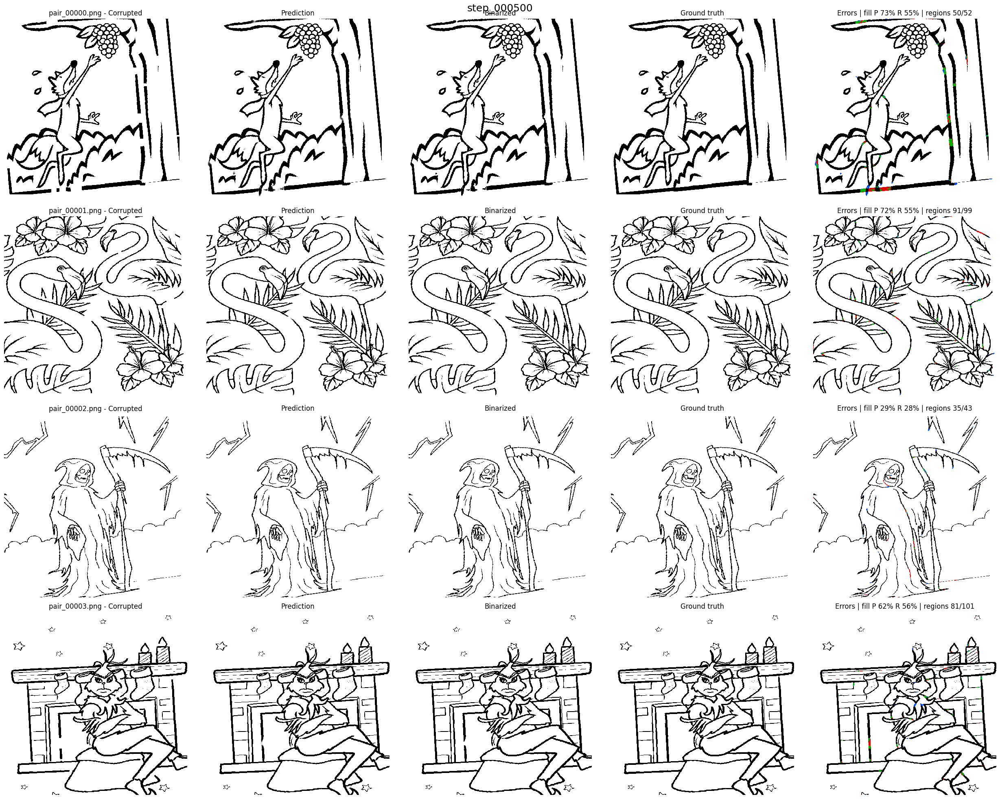

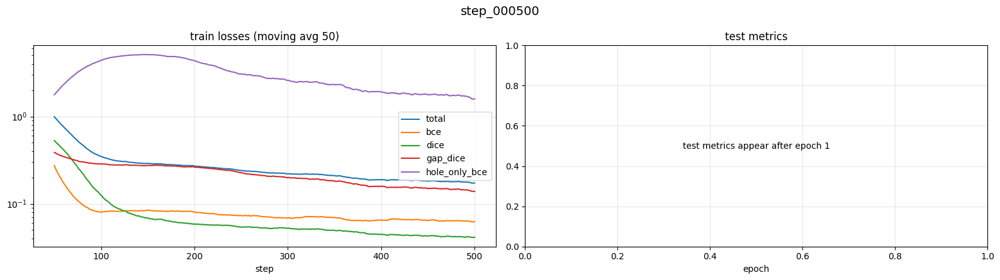

Epoch [1/30] Step [500/2250] total=0.1600 bce=0.0615 dice=0.0440 hole_only=0.9519 hole_frac=0.0022
Epoch [1/30] Step [510/2250] total=0.1714 bce=0.0657 dice=0.0372 hole_only=1.3713 hole_frac=0.0029
Epoch [1/30] Step [520/2250] total=0.1462 bce=0.0457 dice=0.0359 hole_only=1.6653 hole_frac=0.0022
Epoch [1/30] Step [530/2250] total=0.1286 bce=0.0391 dice=0.0302 hole_only=1.1487 hole_frac=0.0026
Epoch [1/30] Step [540/2250] total=0.1602 bce=0.0601 dice=0.0395 hole_only=1.1470 hole_frac=0.0020
Epoch [1/30] Step [550/2250] total=0.1710 bce=0.0671 dice=0.0388 hole_only=1.7165 hole_frac=0.0025
Epoch [1/30] Step [560/2250] total=0.1873 bce=0.0702 dice=0.0387 hole_only=1.8619 hole_frac=0.0028
Epoch [1/30] Step [570/2250] total=0.1838 bce=0.0642 dice=0.0476 hole_only=1.5524 hole_frac=0.0019
Epoch [1/30] Step [580/2250] total=0.2260 bce=0.0803 dice=0.0506 hole_only=2.6453 hole_frac=0.0026
Epoch [1/30] Step [590/2250] total=0.2252 bce=0.0781 dice=0.0578 hole_only=2.2680 hole_frac=0.0017
Epoch [1/3

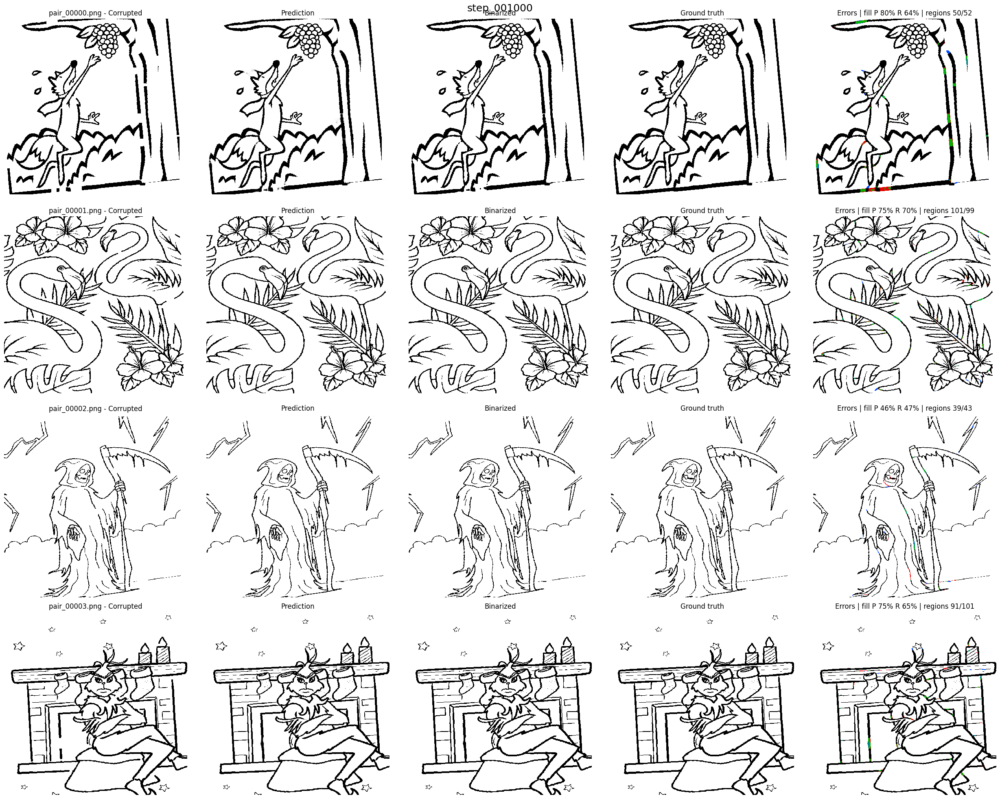

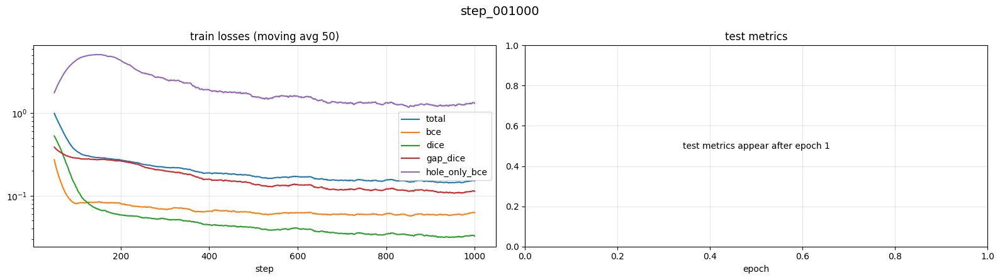

Epoch [1/30] Step [1000/2250] total=0.1153 bce=0.0488 dice=0.0249 hole_only=1.1402 hole_frac=0.0020
Epoch [1/30] Step [1010/2250] total=0.1271 bce=0.0532 dice=0.0256 hole_only=1.1033 hole_frac=0.0029
Epoch [1/30] Step [1020/2250] total=0.1754 bce=0.0725 dice=0.0377 hole_only=1.5525 hole_frac=0.0024
Epoch [1/30] Step [1030/2250] total=0.1308 bce=0.0468 dice=0.0268 hole_only=0.9867 hole_frac=0.0017
Epoch [1/30] Step [1040/2250] total=0.1191 bce=0.0458 dice=0.0245 hole_only=1.1629 hole_frac=0.0020
Epoch [1/30] Step [1050/2250] total=0.1441 bce=0.0629 dice=0.0317 hole_only=1.2474 hole_frac=0.0017
Epoch [1/30] Step [1060/2250] total=0.1614 bce=0.0500 dice=0.0325 hole_only=1.4667 hole_frac=0.0021
Epoch [1/30] Step [1070/2250] total=0.1507 bce=0.0645 dice=0.0283 hole_only=1.6148 hole_frac=0.0025
Epoch [1/30] Step [1080/2250] total=0.1526 bce=0.0626 dice=0.0331 hole_only=1.3239 hole_frac=0.0023
Epoch [1/30] Step [1090/2250] total=0.1425 bce=0.0558 dice=0.0307 hole_only=0.9581 hole_frac=0.0026


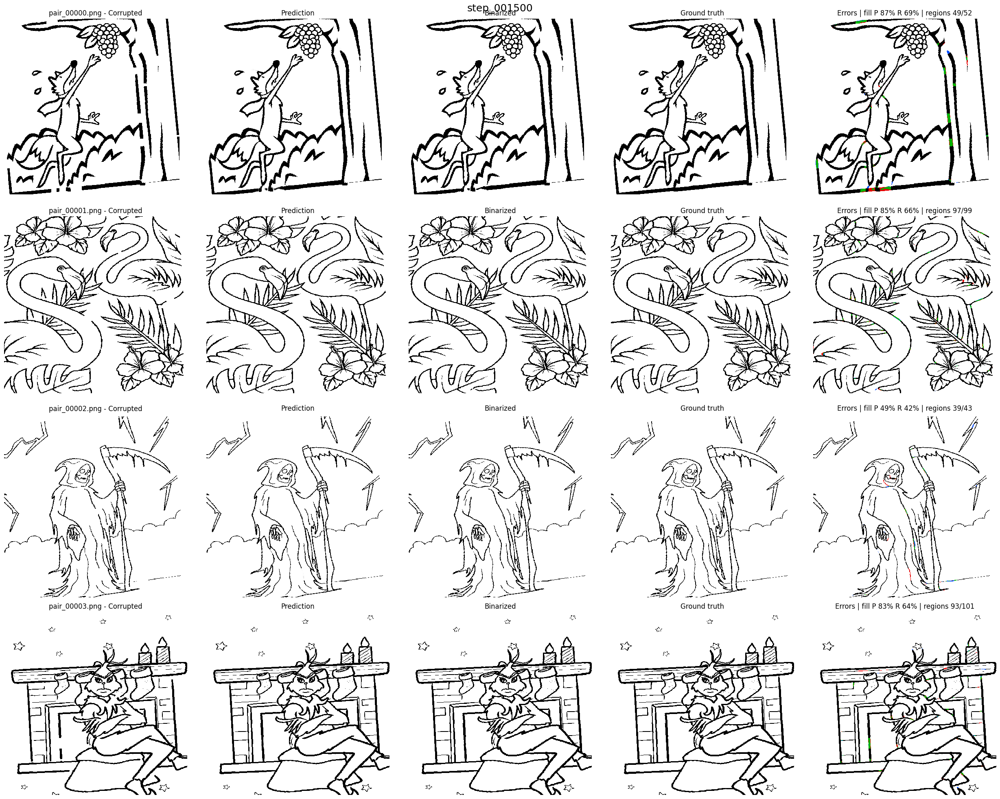

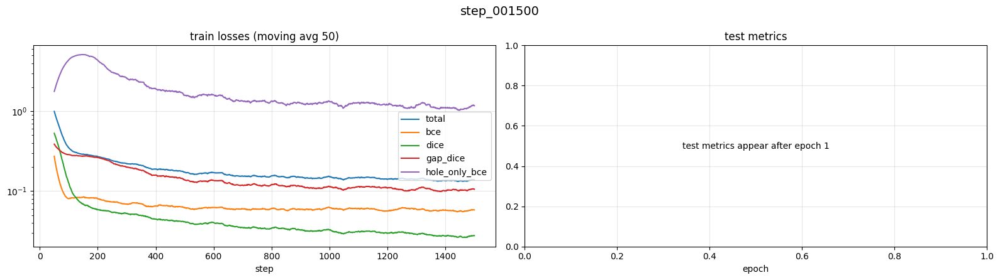

Epoch [1/30] Step [1500/2250] total=0.2022 bce=0.1091 dice=0.0338 hole_only=2.0755 hole_frac=0.0023
Epoch [1/30] Step [1510/2250] total=0.1438 bce=0.0571 dice=0.0315 hole_only=1.0569 hole_frac=0.0027
Epoch [1/30] Step [1520/2250] total=0.1201 bce=0.0482 dice=0.0230 hole_only=0.9576 hole_frac=0.0026
Epoch [1/30] Step [1530/2250] total=0.1269 bce=0.0577 dice=0.0246 hole_only=1.0736 hole_frac=0.0021
Epoch [1/30] Step [1540/2250] total=0.1585 bce=0.0810 dice=0.0310 hole_only=1.5303 hole_frac=0.0021
Epoch [1/30] Step [1550/2250] total=0.1347 bce=0.0565 dice=0.0285 hole_only=0.9995 hole_frac=0.0020
Epoch [1/30] Step [1560/2250] total=0.1390 bce=0.0560 dice=0.0271 hole_only=0.8580 hole_frac=0.0035
Epoch [1/30] Step [1570/2250] total=0.0933 bce=0.0383 dice=0.0159 hole_only=0.6679 hole_frac=0.0020
Epoch [1/30] Step [1580/2250] total=0.1606 bce=0.0627 dice=0.0301 hole_only=0.9416 hole_frac=0.0027
Epoch [1/30] Step [1590/2250] total=0.1354 bce=0.0671 dice=0.0268 hole_only=0.5406 hole_frac=0.0034


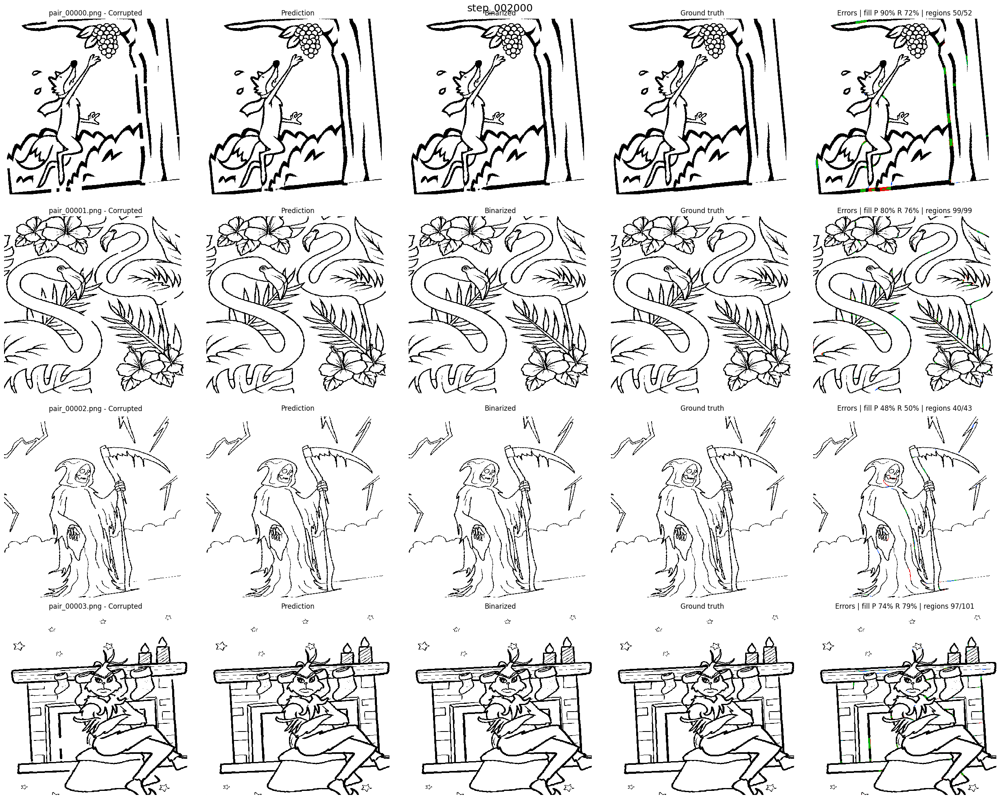

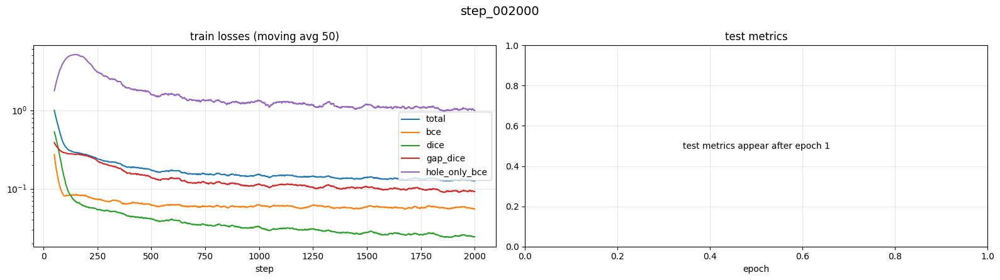

Epoch [1/30] Step [2000/2250] total=0.1444 bce=0.0768 dice=0.0257 hole_only=0.7230 hole_frac=0.0030
Epoch [1/30] Step [2010/2250] total=0.1133 bce=0.0463 dice=0.0223 hole_only=1.0394 hole_frac=0.0044
Epoch [1/30] Step [2020/2250] total=0.1151 bce=0.0517 dice=0.0196 hole_only=1.1339 hole_frac=0.0021
Epoch [1/30] Step [2030/2250] total=0.1547 bce=0.0723 dice=0.0289 hole_only=1.2759 hole_frac=0.0028
Epoch [1/30] Step [2040/2250] total=0.1503 bce=0.0670 dice=0.0306 hole_only=1.2658 hole_frac=0.0026
Epoch [1/30] Step [2050/2250] total=0.1492 bce=0.0746 dice=0.0283 hole_only=1.0568 hole_frac=0.0031
Epoch [1/30] Step [2060/2250] total=0.1251 bce=0.0528 dice=0.0233 hole_only=1.2940 hole_frac=0.0030
Epoch [1/30] Step [2070/2250] total=0.1555 bce=0.0750 dice=0.0271 hole_only=1.0397 hole_frac=0.0022
Epoch [1/30] Step [2080/2250] total=0.1167 bce=0.0545 dice=0.0226 hole_only=0.8576 hole_frac=0.0023
Epoch [1/30] Step [2090/2250] total=0.0911 bce=0.0399 dice=0.0168 hole_only=0.7790 hole_frac=0.0037


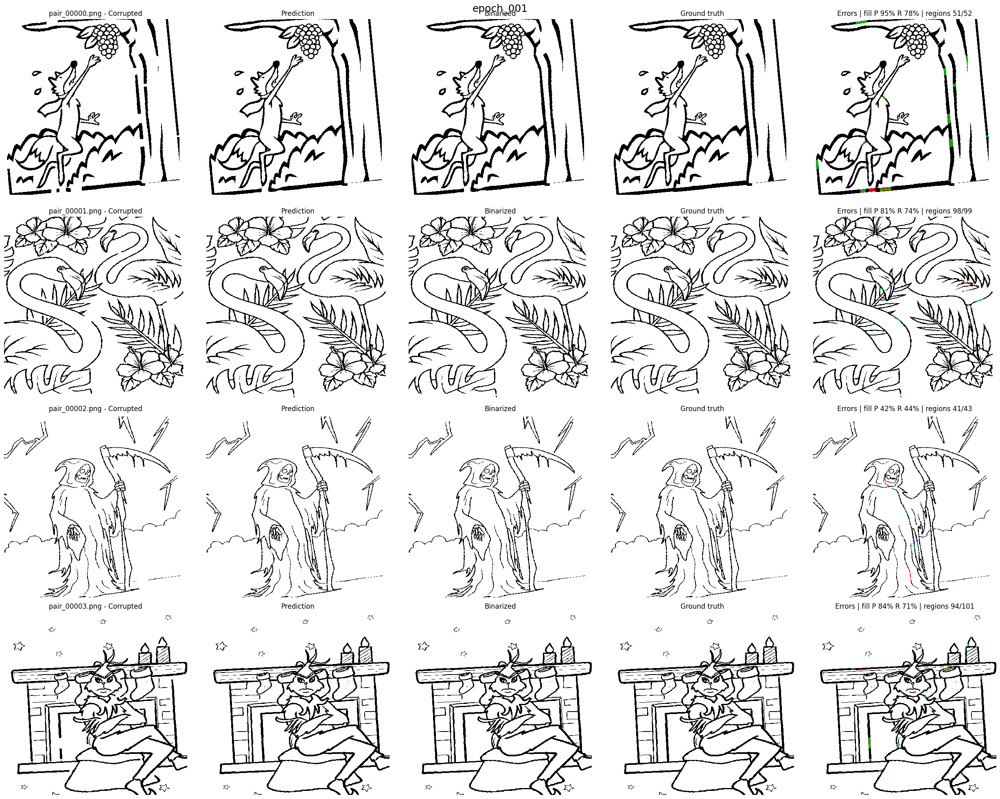

Epoch [2/30] Step [0/2250] total=0.1523 bce=0.0540 dice=0.0312 hole_only=1.6021 hole_frac=0.0029
Epoch [2/30] Step [10/2250] total=0.1462 bce=0.0661 dice=0.0296 hole_only=1.0058 hole_frac=0.0030
Epoch [2/30] Step [20/2250] total=0.1202 bce=0.0575 dice=0.0240 hole_only=0.9682 hole_frac=0.0025
Epoch [2/30] Step [30/2250] total=0.1392 bce=0.0637 dice=0.0242 hole_only=0.9552 hole_frac=0.0032
Epoch [2/30] Step [40/2250] total=0.1150 bce=0.0497 dice=0.0221 hole_only=1.0609 hole_frac=0.0022
Epoch [2/30] Step [50/2250] total=0.1578 bce=0.0639 dice=0.0335 hole_only=1.5828 hole_frac=0.0015
Epoch [2/30] Step [60/2250] total=0.0861 bce=0.0384 dice=0.0166 hole_only=0.5453 hole_frac=0.0022
Epoch [2/30] Step [70/2250] total=0.1373 bce=0.0677 dice=0.0252 hole_only=1.2207 hole_frac=0.0026
Epoch [2/30] Step [80/2250] total=0.1111 bce=0.0515 dice=0.0210 hole_only=0.7393 hole_frac=0.0027
Epoch [2/30] Step [90/2250] total=0.1505 bce=0.0681 dice=0.0268 hole_only=1.2633 hole_frac=0.0020
Epoch [2/30] Step [10

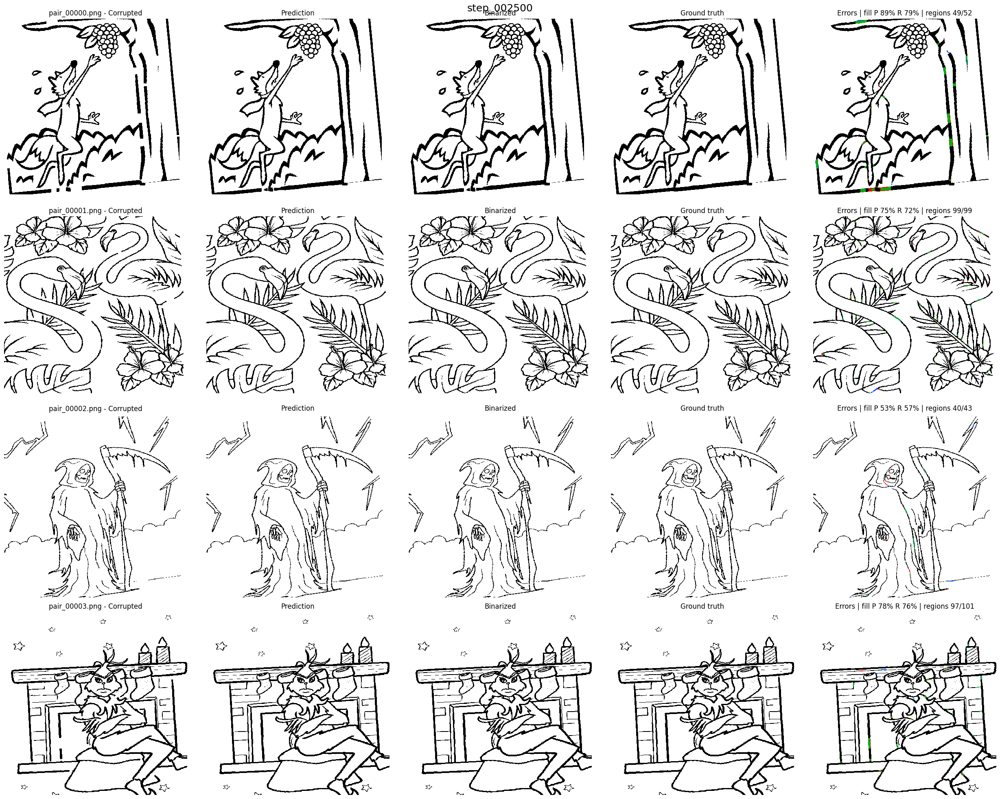

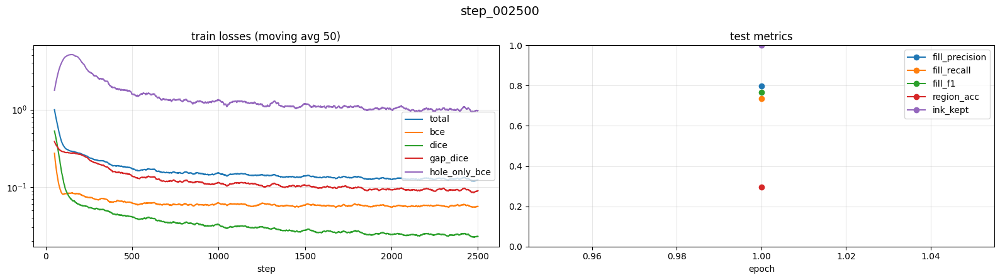

Epoch [2/30] Step [250/2250] total=0.0998 bce=0.0491 dice=0.0174 hole_only=0.6290 hole_frac=0.0023
Epoch [2/30] Step [260/2250] total=0.1010 bce=0.0487 dice=0.0175 hole_only=0.8385 hole_frac=0.0034
Epoch [2/30] Step [270/2250] total=0.1046 bce=0.0513 dice=0.0192 hole_only=0.8066 hole_frac=0.0025
Epoch [2/30] Step [280/2250] total=0.1022 bce=0.0466 dice=0.0192 hole_only=0.6684 hole_frac=0.0021
Epoch [2/30] Step [290/2250] total=0.1767 bce=0.0878 dice=0.0348 hole_only=1.3956 hole_frac=0.0017
Epoch [2/30] Step [300/2250] total=0.1418 bce=0.0639 dice=0.0277 hole_only=0.8203 hole_frac=0.0027
Epoch [2/30] Step [310/2250] total=0.1701 bce=0.0809 dice=0.0315 hole_only=1.9365 hole_frac=0.0019
Epoch [2/30] Step [320/2250] total=0.1099 bce=0.0497 dice=0.0195 hole_only=1.0008 hole_frac=0.0021
Epoch [2/30] Step [330/2250] total=0.1608 bce=0.0696 dice=0.0315 hole_only=1.5034 hole_frac=0.0020
Epoch [2/30] Step [340/2250] total=0.1125 bce=0.0421 dice=0.0209 hole_only=0.8510 hole_frac=0.0018
Epoch [2/3

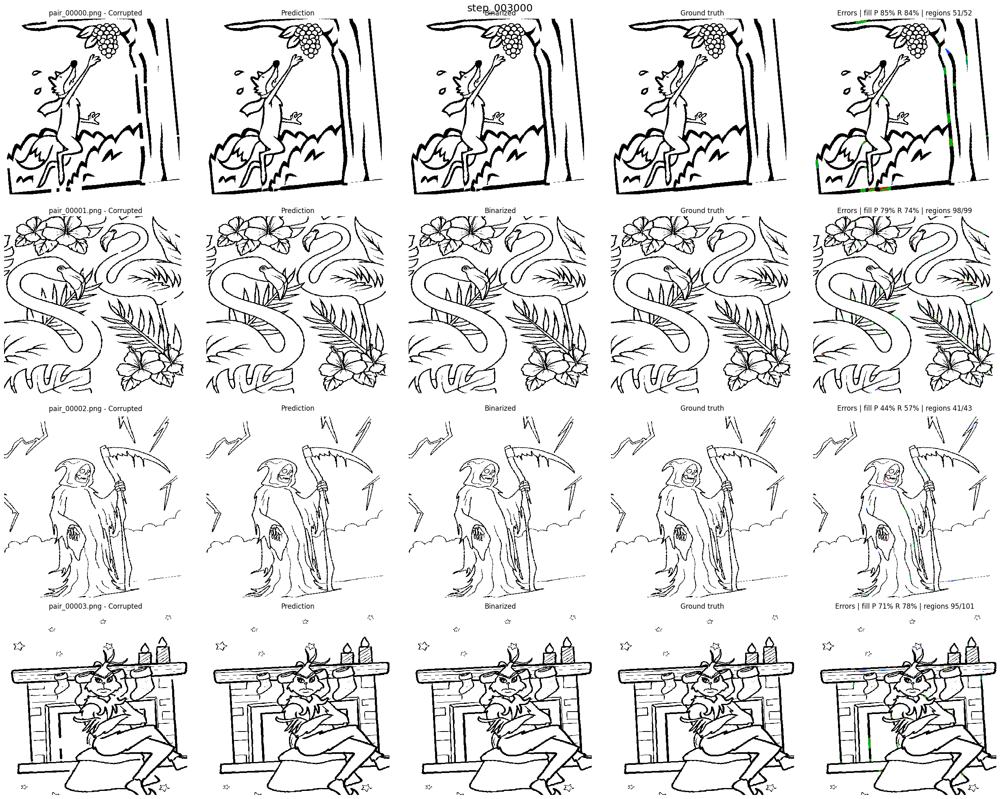

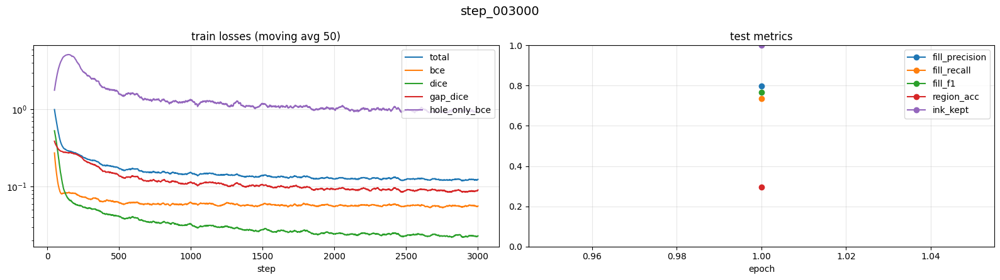

Epoch [2/30] Step [750/2250] total=0.1435 bce=0.0578 dice=0.0260 hole_only=0.9578 hole_frac=0.0017
Epoch [2/30] Step [760/2250] total=0.1355 bce=0.0574 dice=0.0250 hole_only=1.2604 hole_frac=0.0018
Epoch [2/30] Step [770/2250] total=0.1015 bce=0.0392 dice=0.0187 hole_only=0.8312 hole_frac=0.0028
Epoch [2/30] Step [780/2250] total=0.1130 bce=0.0476 dice=0.0222 hole_only=1.0445 hole_frac=0.0029
Epoch [2/30] Step [790/2250] total=0.1389 bce=0.0561 dice=0.0283 hole_only=0.9731 hole_frac=0.0019
Epoch [2/30] Step [800/2250] total=0.1307 bce=0.0611 dice=0.0230 hole_only=0.6902 hole_frac=0.0034
Epoch [2/30] Step [810/2250] total=0.1143 bce=0.0543 dice=0.0209 hole_only=0.8615 hole_frac=0.0031
Epoch [2/30] Step [820/2250] total=0.1221 bce=0.0582 dice=0.0241 hole_only=1.0304 hole_frac=0.0019
Epoch [2/30] Step [830/2250] total=0.1428 bce=0.0658 dice=0.0258 hole_only=0.9468 hole_frac=0.0027
Epoch [2/30] Step [840/2250] total=0.1336 bce=0.0634 dice=0.0269 hole_only=0.8764 hole_frac=0.0021
Epoch [2/3

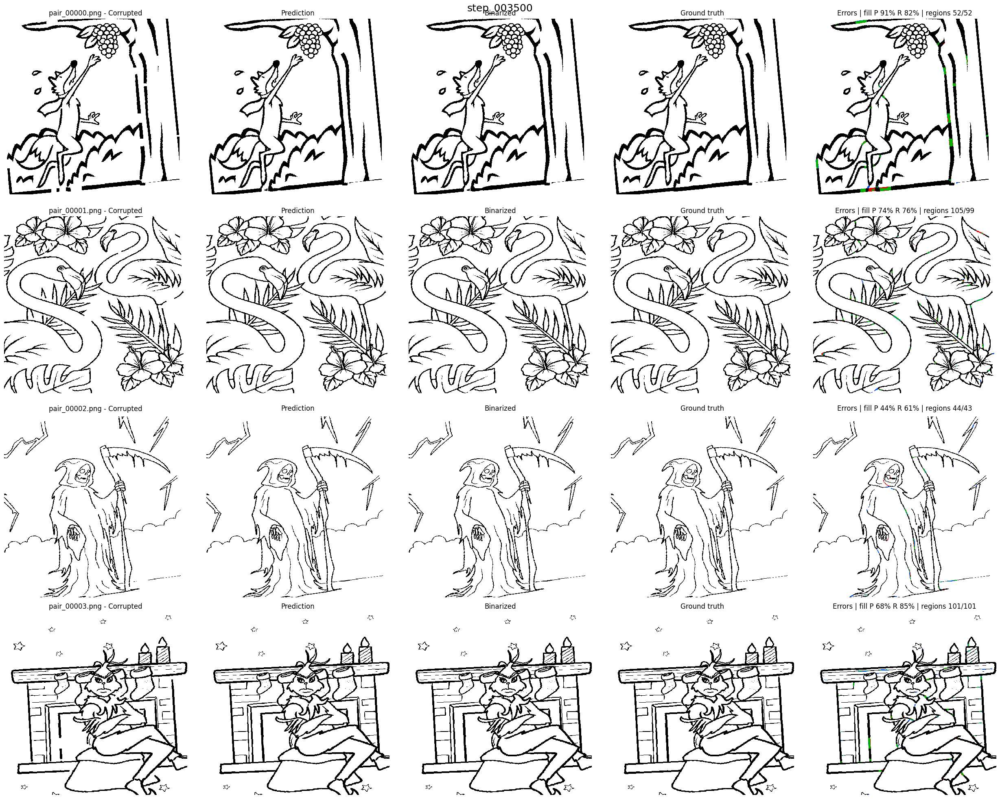

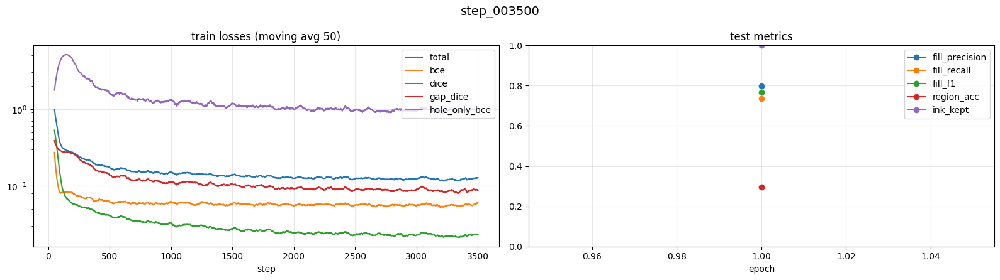

Epoch [2/30] Step [1250/2250] total=0.1071 bce=0.0424 dice=0.0219 hole_only=0.8939 hole_frac=0.0030
Epoch [2/30] Step [1260/2250] total=0.1285 bce=0.0587 dice=0.0256 hole_only=0.9378 hole_frac=0.0024
Epoch [2/30] Step [1270/2250] total=0.1491 bce=0.0607 dice=0.0268 hole_only=0.9837 hole_frac=0.0026
Epoch [2/30] Step [1280/2250] total=0.1498 bce=0.0646 dice=0.0263 hole_only=1.1297 hole_frac=0.0020
Epoch [2/30] Step [1290/2250] total=0.1343 bce=0.0677 dice=0.0245 hole_only=0.8145 hole_frac=0.0033
Epoch [2/30] Step [1300/2250] total=0.1471 bce=0.0687 dice=0.0340 hole_only=1.1337 hole_frac=0.0027
Epoch [2/30] Step [1310/2250] total=0.1117 bce=0.0471 dice=0.0195 hole_only=1.0477 hole_frac=0.0018
Epoch [2/30] Step [1320/2250] total=0.1383 bce=0.0654 dice=0.0241 hole_only=0.9523 hole_frac=0.0037
Epoch [2/30] Step [1330/2250] total=0.1236 bce=0.0562 dice=0.0225 hole_only=0.9810 hole_frac=0.0025
Epoch [2/30] Step [1340/2250] total=0.1150 bce=0.0566 dice=0.0200 hole_only=0.8013 hole_frac=0.0023


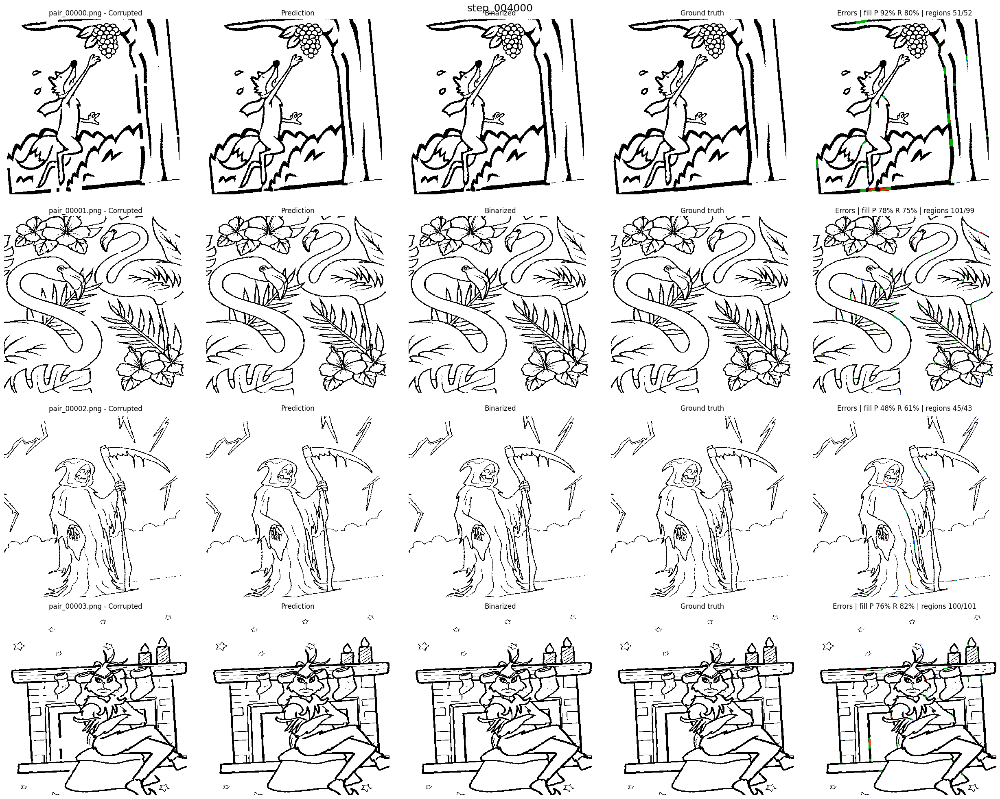

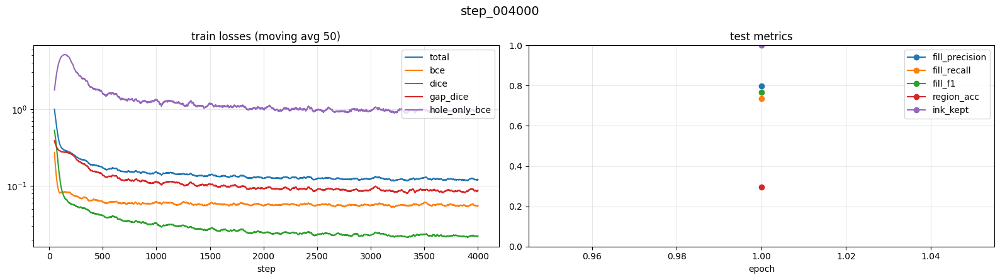

Epoch [2/30] Step [1750/2250] total=0.1194 bce=0.0607 dice=0.0206 hole_only=0.9064 hole_frac=0.0028
Epoch [2/30] Step [1760/2250] total=0.1349 bce=0.0674 dice=0.0238 hole_only=1.0800 hole_frac=0.0023
Epoch [2/30] Step [1770/2250] total=0.1013 bce=0.0477 dice=0.0178 hole_only=0.9208 hole_frac=0.0018
Epoch [2/30] Step [1780/2250] total=0.1571 bce=0.0778 dice=0.0284 hole_only=1.2297 hole_frac=0.0019
Epoch [2/30] Step [1790/2250] total=0.1479 bce=0.0745 dice=0.0254 hole_only=1.1283 hole_frac=0.0032
Epoch [2/30] Step [1800/2250] total=0.1039 bce=0.0463 dice=0.0184 hole_only=1.0729 hole_frac=0.0013
Epoch [2/30] Step [1810/2250] total=0.1133 bce=0.0476 dice=0.0225 hole_only=0.7616 hole_frac=0.0035
Epoch [2/30] Step [1820/2250] total=0.1099 bce=0.0554 dice=0.0194 hole_only=0.7140 hole_frac=0.0023
Epoch [2/30] Step [1830/2250] total=0.1074 bce=0.0551 dice=0.0198 hole_only=0.6916 hole_frac=0.0030
Epoch [2/30] Step [1840/2250] total=0.1674 bce=0.0861 dice=0.0314 hole_only=1.1661 hole_frac=0.0018


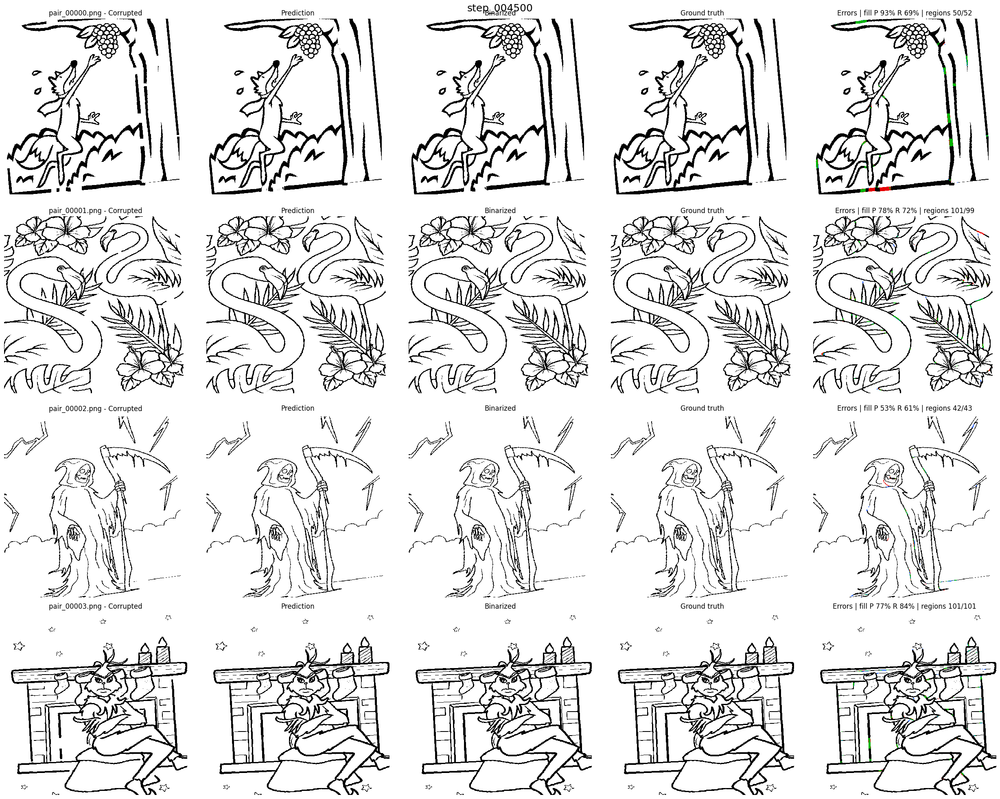

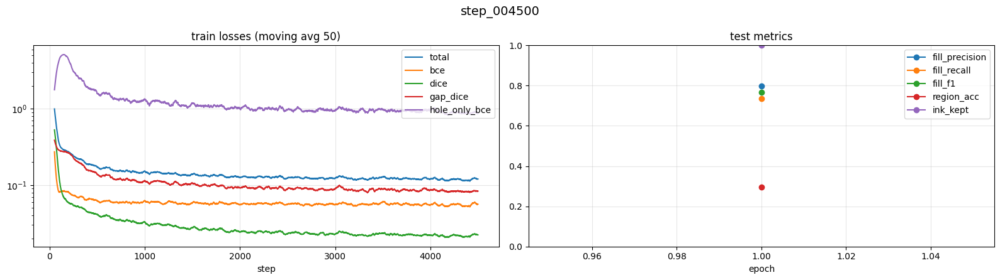

Epoch [2/30]
  TEST fill_precision=0.7950 fill_recall=0.7773 fill_f1=0.7861 ink_kept=1.0000 px_f1=0.9933 ink_ratio=0.9993 region_acc=0.3500 region_recovery=0.9006 regions_pred=52.2080 regions_gt=53.4250


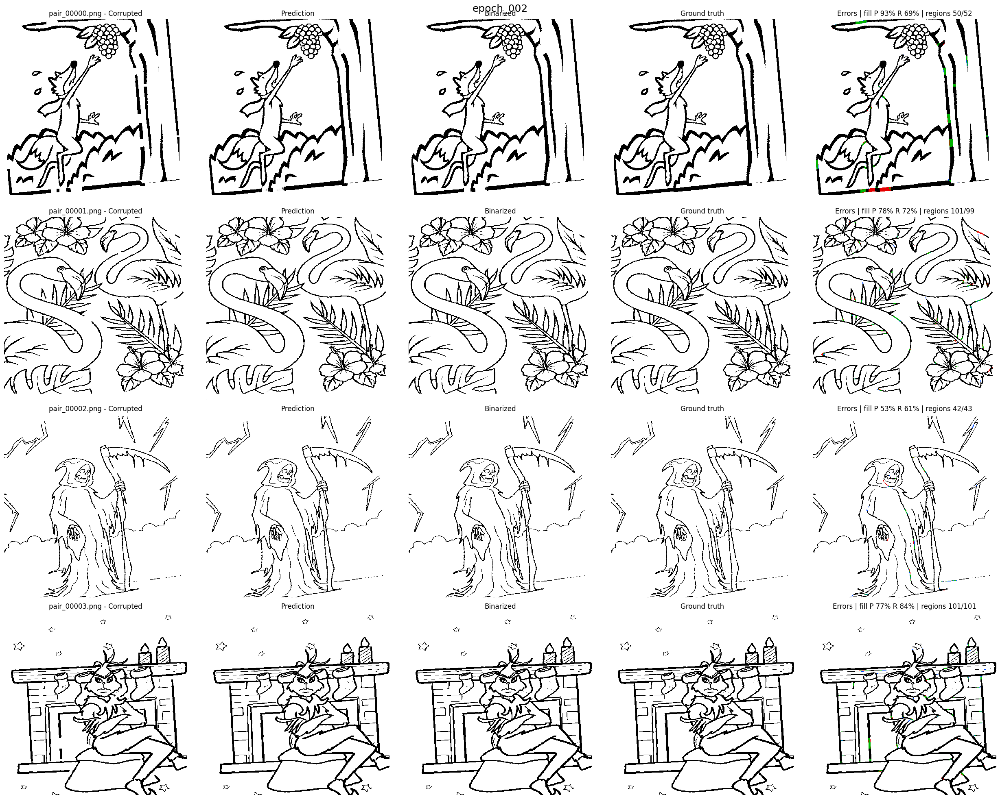

Epoch [3/30] Step [0/2250] total=0.1388 bce=0.0698 dice=0.0247 hole_only=1.0066 hole_frac=0.0023
Epoch [3/30] Step [10/2250] total=0.1361 bce=0.0712 dice=0.0244 hole_only=0.8209 hole_frac=0.0028
Epoch [3/30] Step [20/2250] total=0.1116 bce=0.0570 dice=0.0203 hole_only=0.7357 hole_frac=0.0021
Epoch [3/30] Step [30/2250] total=0.1129 bce=0.0558 dice=0.0195 hole_only=0.7579 hole_frac=0.0032
Epoch [3/30] Step [40/2250] total=0.1120 bce=0.0538 dice=0.0212 hole_only=0.9436 hole_frac=0.0035
Epoch [3/30] Step [50/2250] total=0.1231 bce=0.0665 dice=0.0219 hole_only=1.0799 hole_frac=0.0040
Epoch [3/30] Step [60/2250] total=0.1661 bce=0.0706 dice=0.0266 hole_only=1.7026 hole_frac=0.0019
Epoch [3/30] Step [70/2250] total=0.1160 bce=0.0509 dice=0.0196 hole_only=0.9903 hole_frac=0.0018
Epoch [3/30] Step [80/2250] total=0.0918 bce=0.0455 dice=0.0172 hole_only=0.5400 hole_frac=0.0034
Epoch [3/30] Step [90/2250] total=0.0990 bce=0.0522 dice=0.0178 hole_only=0.7655 hole_frac=0.0023
Epoch [3/30] Step [10

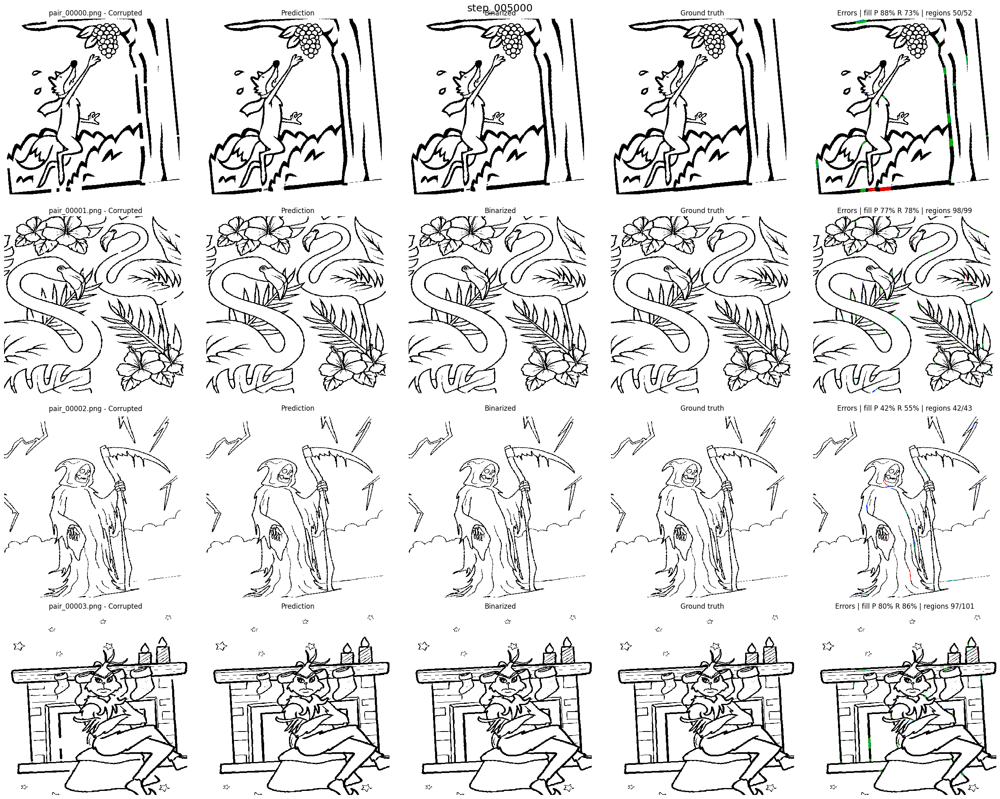

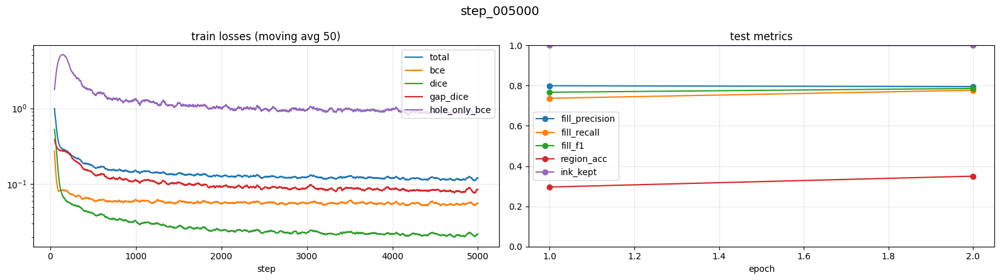

Epoch [3/30] Step [500/2250] total=0.1295 bce=0.0606 dice=0.0246 hole_only=0.9021 hole_frac=0.0018
Epoch [3/30] Step [510/2250] total=0.1068 bce=0.0554 dice=0.0190 hole_only=0.5835 hole_frac=0.0028
Epoch [3/30] Step [520/2250] total=0.1342 bce=0.0659 dice=0.0236 hole_only=1.0774 hole_frac=0.0022
Epoch [3/30] Step [530/2250] total=0.1420 bce=0.0748 dice=0.0247 hole_only=1.0057 hole_frac=0.0020
Epoch [3/30] Step [540/2250] total=0.1124 bce=0.0519 dice=0.0201 hole_only=1.0033 hole_frac=0.0019
Epoch [3/30] Step [550/2250] total=0.1147 bce=0.0443 dice=0.0191 hole_only=0.6065 hole_frac=0.0038
Epoch [3/30] Step [560/2250] total=0.1538 bce=0.0851 dice=0.0245 hole_only=1.1734 hole_frac=0.0033
Epoch [3/30] Step [570/2250] total=0.1306 bce=0.0629 dice=0.0240 hole_only=1.2106 hole_frac=0.0021
Epoch [3/30] Step [580/2250] total=0.1098 bce=0.0507 dice=0.0211 hole_only=0.7472 hole_frac=0.0026
Epoch [3/30] Step [590/2250] total=0.1389 bce=0.0700 dice=0.0254 hole_only=1.1514 hole_frac=0.0025
Epoch [3/3

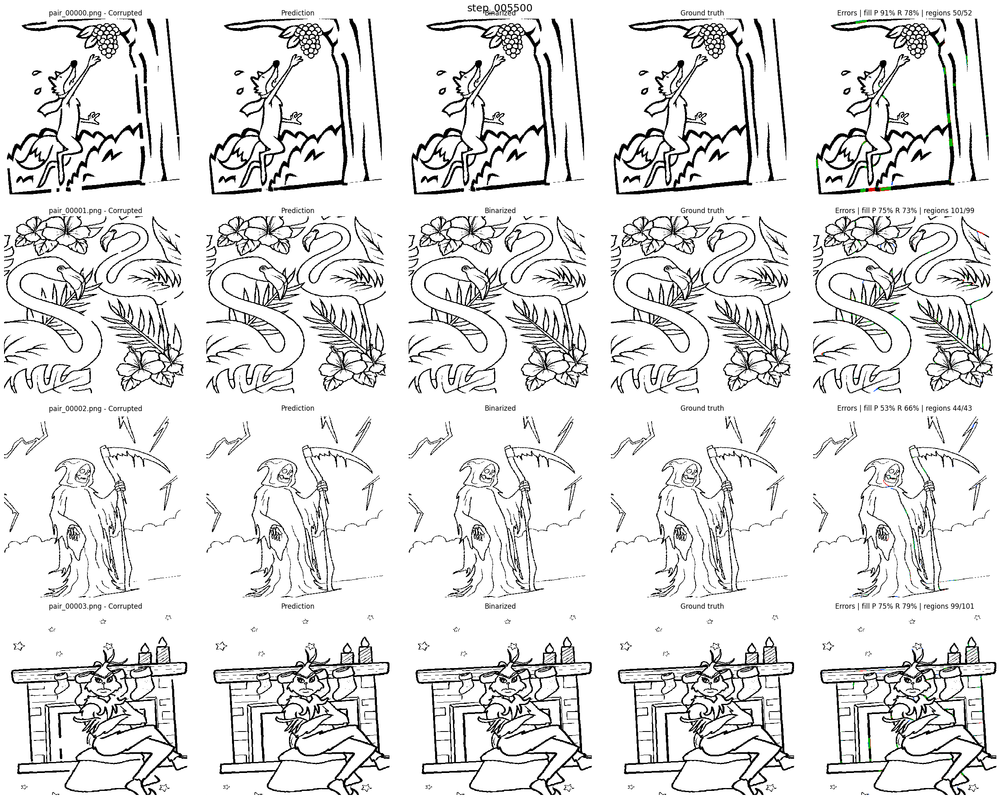

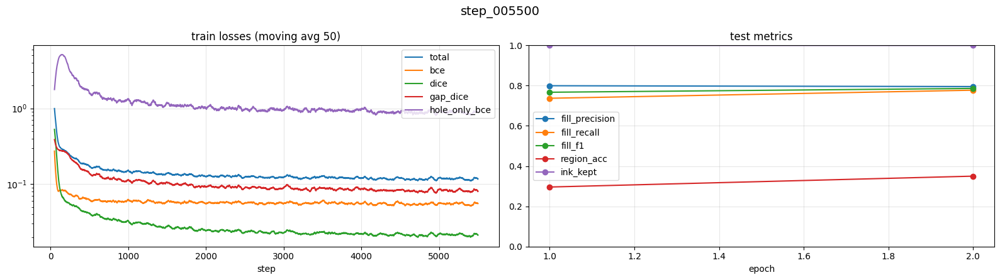

Epoch [3/30] Step [1000/2250] total=0.1000 bce=0.0443 dice=0.0172 hole_only=0.6671 hole_frac=0.0027
Epoch [3/30] Step [1010/2250] total=0.1081 bce=0.0448 dice=0.0209 hole_only=0.9554 hole_frac=0.0025
Epoch [3/30] Step [1020/2250] total=0.1199 bce=0.0643 dice=0.0220 hole_only=0.7602 hole_frac=0.0023
Epoch [3/30] Step [1030/2250] total=0.1364 bce=0.0689 dice=0.0252 hole_only=0.9213 hole_frac=0.0025
Epoch [3/30] Step [1040/2250] total=0.1108 bce=0.0524 dice=0.0193 hole_only=0.6314 hole_frac=0.0028
Epoch [3/30] Step [1050/2250] total=0.1095 bce=0.0506 dice=0.0189 hole_only=1.1619 hole_frac=0.0018
Epoch [3/30] Step [1060/2250] total=0.0855 bce=0.0429 dice=0.0146 hole_only=0.5486 hole_frac=0.0037
Epoch [3/30] Step [1070/2250] total=0.1007 bce=0.0449 dice=0.0187 hole_only=0.8561 hole_frac=0.0024
Epoch [3/30] Step [1080/2250] total=0.1110 bce=0.0525 dice=0.0202 hole_only=0.8679 hole_frac=0.0019
Epoch [3/30] Step [1090/2250] total=0.1233 bce=0.0548 dice=0.0224 hole_only=0.7725 hole_frac=0.0025


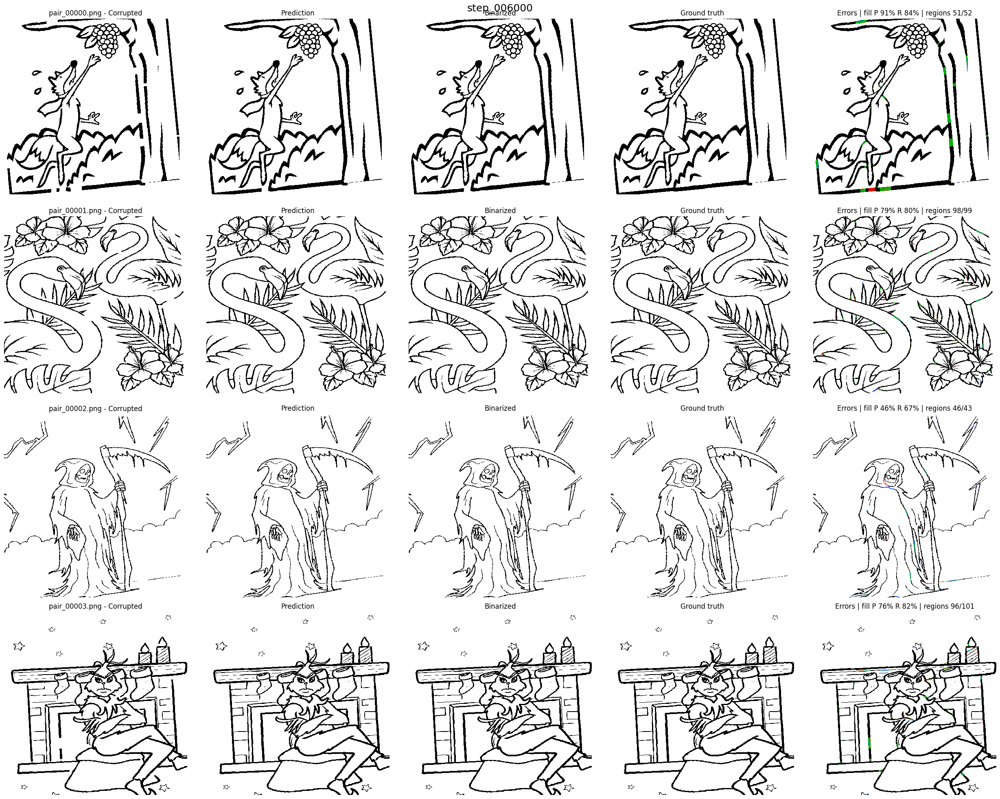

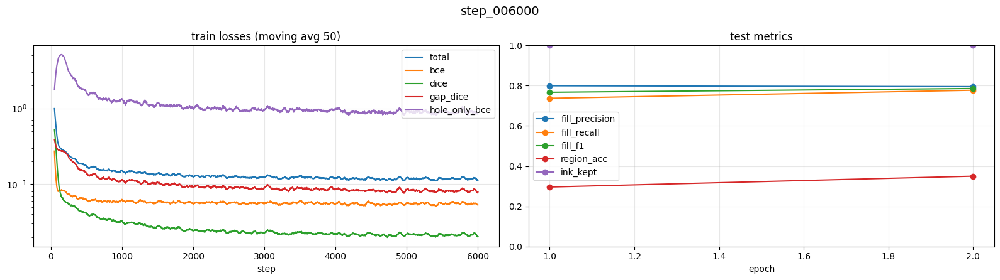

Epoch [3/30] Step [1500/2250] total=0.1304 bce=0.0518 dice=0.0222 hole_only=0.9359 hole_frac=0.0017
Epoch [3/30] Step [1510/2250] total=0.1091 bce=0.0512 dice=0.0191 hole_only=0.5812 hole_frac=0.0036
Epoch [3/30] Step [1520/2250] total=0.1166 bce=0.0504 dice=0.0208 hole_only=0.7832 hole_frac=0.0035
Epoch [3/30] Step [1530/2250] total=0.0957 bce=0.0443 dice=0.0172 hole_only=0.7823 hole_frac=0.0026
Epoch [3/30] Step [1540/2250] total=0.1226 bce=0.0562 dice=0.0229 hole_only=1.2220 hole_frac=0.0027
Epoch [3/30] Step [1550/2250] total=0.1246 bce=0.0579 dice=0.0218 hole_only=0.7852 hole_frac=0.0018
Epoch [3/30] Step [1560/2250] total=0.1551 bce=0.0647 dice=0.0316 hole_only=1.3772 hole_frac=0.0021
Epoch [3/30] Step [1570/2250] total=0.1008 bce=0.0517 dice=0.0178 hole_only=0.6655 hole_frac=0.0020
Epoch [3/30] Step [1580/2250] total=0.1033 bce=0.0522 dice=0.0188 hole_only=0.6564 hole_frac=0.0025
Epoch [3/30] Step [1590/2250] total=0.1175 bce=0.0534 dice=0.0227 hole_only=0.9336 hole_frac=0.0029


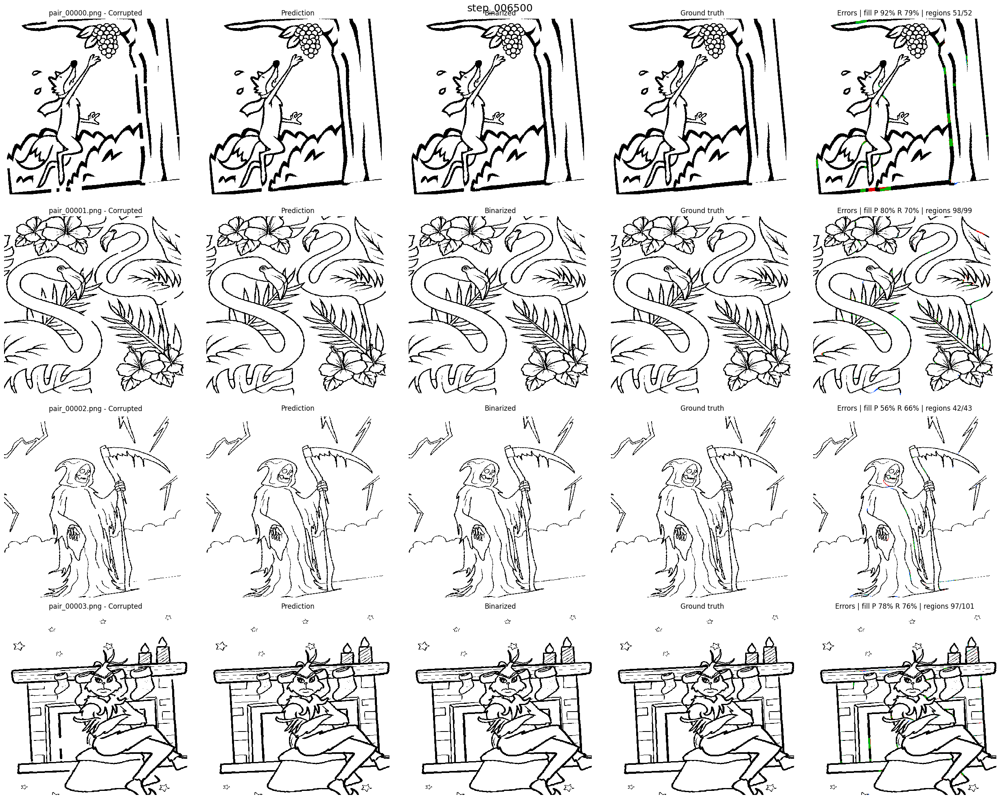

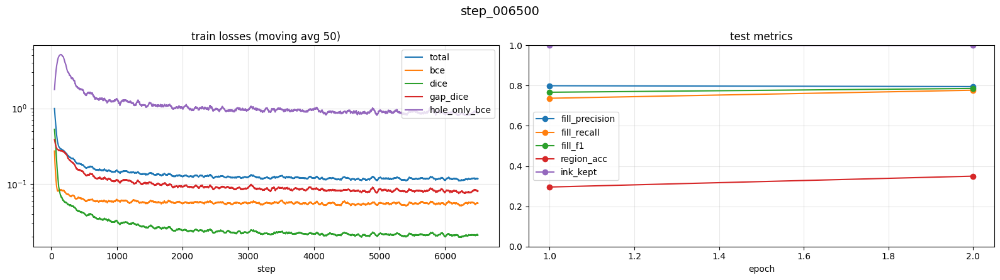

Epoch [3/30] Step [2000/2250] total=0.1250 bce=0.0612 dice=0.0221 hole_only=1.1924 hole_frac=0.0020
Epoch [3/30] Step [2010/2250] total=0.1455 bce=0.0679 dice=0.0225 hole_only=1.0786 hole_frac=0.0036
Epoch [3/30] Step [2020/2250] total=0.1000 bce=0.0439 dice=0.0176 hole_only=0.7843 hole_frac=0.0026
Epoch [3/30] Step [2030/2250] total=0.1258 bce=0.0586 dice=0.0204 hole_only=1.0001 hole_frac=0.0023
Epoch [3/30] Step [2040/2250] total=0.1284 bce=0.0578 dice=0.0198 hole_only=1.2647 hole_frac=0.0016
Epoch [3/30] Step [2050/2250] total=0.1224 bce=0.0576 dice=0.0224 hole_only=1.0486 hole_frac=0.0028
Epoch [3/30] Step [2060/2250] total=0.1121 bce=0.0507 dice=0.0175 hole_only=0.6474 hole_frac=0.0025
Epoch [3/30] Step [2070/2250] total=0.1239 bce=0.0545 dice=0.0211 hole_only=1.4549 hole_frac=0.0031
Epoch [3/30] Step [2080/2250] total=0.1042 bce=0.0532 dice=0.0195 hole_only=0.7767 hole_frac=0.0022
Epoch [3/30] Step [2090/2250] total=0.1355 bce=0.0615 dice=0.0216 hole_only=1.1656 hole_frac=0.0025


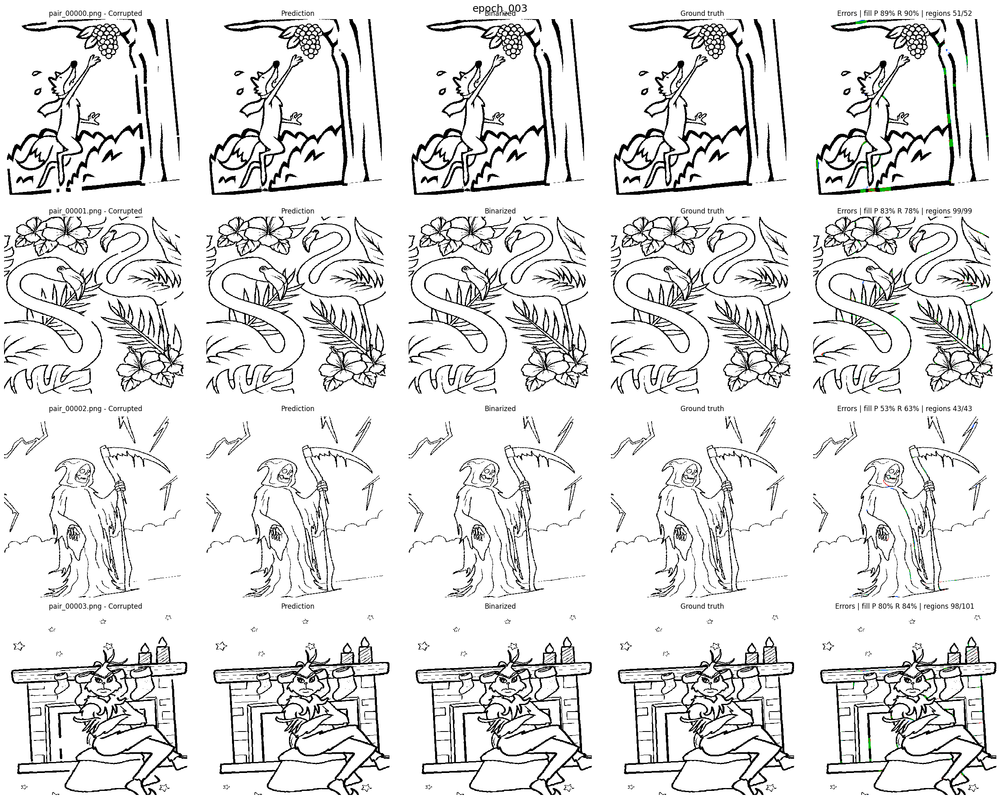

Epoch [4/30] Step [0/2250] total=0.1073 bce=0.0553 dice=0.0194 hole_only=0.4944 hole_frac=0.0027
Epoch [4/30] Step [10/2250] total=0.0870 bce=0.0428 dice=0.0154 hole_only=1.0710 hole_frac=0.0014
Epoch [4/30] Step [20/2250] total=0.0987 bce=0.0488 dice=0.0190 hole_only=0.7182 hole_frac=0.0018
Epoch [4/30] Step [30/2250] total=0.1105 bce=0.0561 dice=0.0208 hole_only=0.9295 hole_frac=0.0023
Epoch [4/30] Step [40/2250] total=0.1270 bce=0.0646 dice=0.0236 hole_only=0.6884 hole_frac=0.0020
Epoch [4/30] Step [50/2250] total=0.0926 bce=0.0429 dice=0.0174 hole_only=0.6590 hole_frac=0.0028
Epoch [4/30] Step [60/2250] total=0.1355 bce=0.0659 dice=0.0262 hole_only=1.1333 hole_frac=0.0017
Epoch [4/30] Step [70/2250] total=0.1014 bce=0.0531 dice=0.0170 hole_only=0.6036 hole_frac=0.0040
Epoch [4/30] Step [80/2250] total=0.1189 bce=0.0541 dice=0.0248 hole_only=0.8949 hole_frac=0.0024
Epoch [4/30] Step [90/2250] total=0.1008 bce=0.0441 dice=0.0193 hole_only=0.7928 hole_frac=0.0020
Epoch [4/30] Step [10

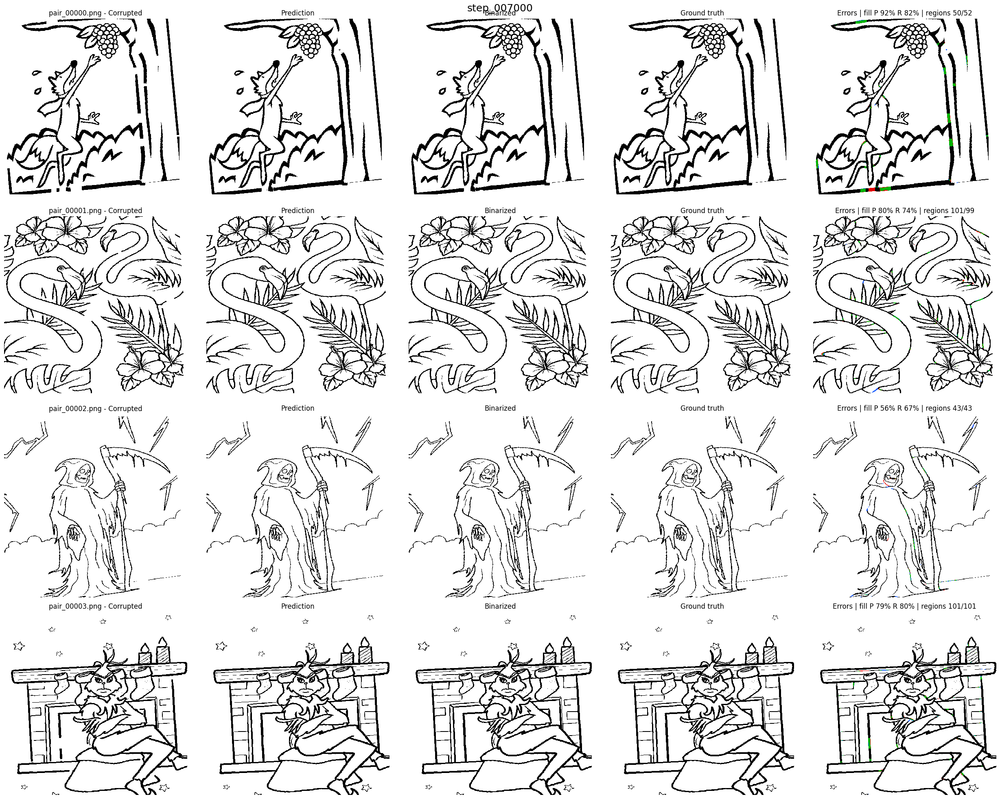

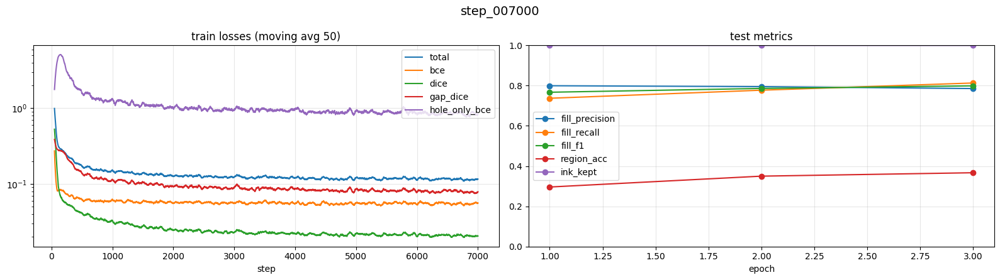

Epoch [4/30] Step [250/2250] total=0.1338 bce=0.0657 dice=0.0231 hole_only=1.0401 hole_frac=0.0032
Epoch [4/30] Step [260/2250] total=0.1159 bce=0.0519 dice=0.0184 hole_only=0.9908 hole_frac=0.0012
Epoch [4/30] Step [270/2250] total=0.1124 bce=0.0470 dice=0.0200 hole_only=1.2994 hole_frac=0.0015
Epoch [4/30] Step [280/2250] total=0.0975 bce=0.0511 dice=0.0165 hole_only=0.4654 hole_frac=0.0031
Epoch [4/30] Step [290/2250] total=0.1204 bce=0.0510 dice=0.0233 hole_only=0.8375 hole_frac=0.0032
Epoch [4/30] Step [300/2250] total=0.0858 bce=0.0420 dice=0.0176 hole_only=0.4326 hole_frac=0.0047
Epoch [4/30] Step [310/2250] total=0.1374 bce=0.0608 dice=0.0284 hole_only=1.0720 hole_frac=0.0020
Epoch [4/30] Step [320/2250] total=0.1353 bce=0.0593 dice=0.0225 hole_only=1.2785 hole_frac=0.0024
Epoch [4/30] Step [330/2250] total=0.1326 bce=0.0624 dice=0.0238 hole_only=1.0063 hole_frac=0.0021
Epoch [4/30] Step [340/2250] total=0.0876 bce=0.0390 dice=0.0158 hole_only=0.7755 hole_frac=0.0024
Epoch [4/3

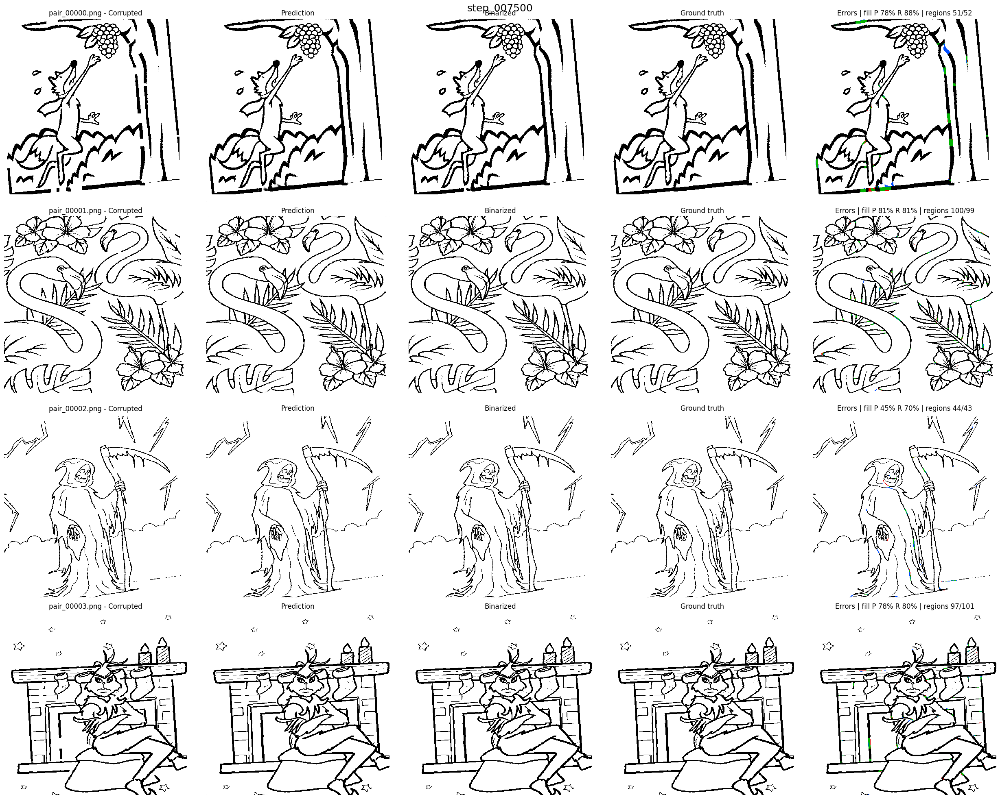

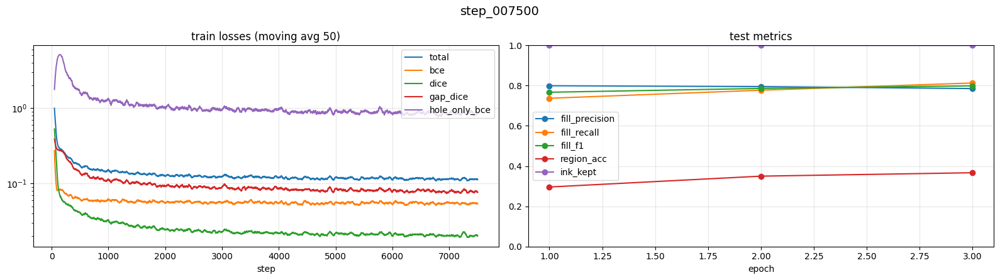

Epoch [4/30] Step [750/2250] total=0.1410 bce=0.0714 dice=0.0282 hole_only=0.8686 hole_frac=0.0025
Epoch [4/30] Step [760/2250] total=0.0913 bce=0.0481 dice=0.0147 hole_only=0.5942 hole_frac=0.0028
Epoch [4/30] Step [770/2250] total=0.1057 bce=0.0503 dice=0.0178 hole_only=0.8805 hole_frac=0.0020
Epoch [4/30] Step [780/2250] total=0.1460 bce=0.0657 dice=0.0252 hole_only=1.6550 hole_frac=0.0013
Epoch [4/30] Step [790/2250] total=0.1095 bce=0.0497 dice=0.0185 hole_only=0.9811 hole_frac=0.0022
Epoch [4/30] Step [800/2250] total=0.1041 bce=0.0469 dice=0.0184 hole_only=0.8731 hole_frac=0.0027
Epoch [4/30] Step [810/2250] total=0.1231 bce=0.0560 dice=0.0216 hole_only=0.9679 hole_frac=0.0030
Epoch [4/30] Step [820/2250] total=0.0972 bce=0.0460 dice=0.0202 hole_only=0.6808 hole_frac=0.0028
Epoch [4/30] Step [830/2250] total=0.0918 bce=0.0365 dice=0.0185 hole_only=0.6316 hole_frac=0.0044
Epoch [4/30] Step [840/2250] total=0.0941 bce=0.0461 dice=0.0174 hole_only=0.6444 hole_frac=0.0018
Epoch [4/3

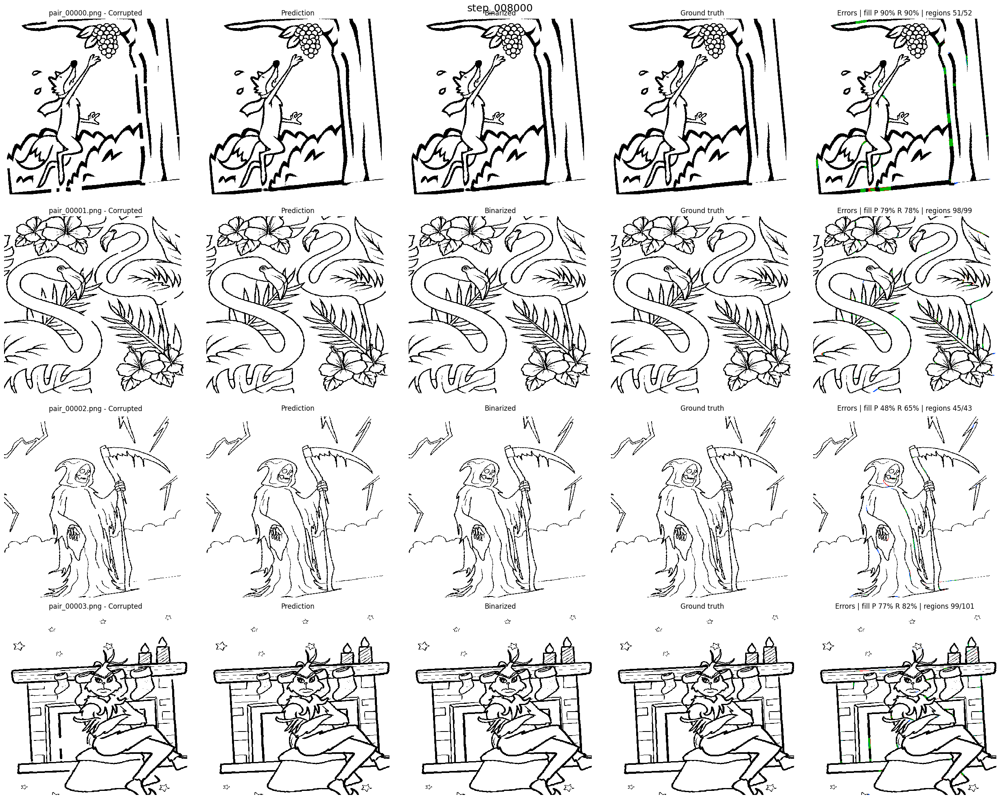

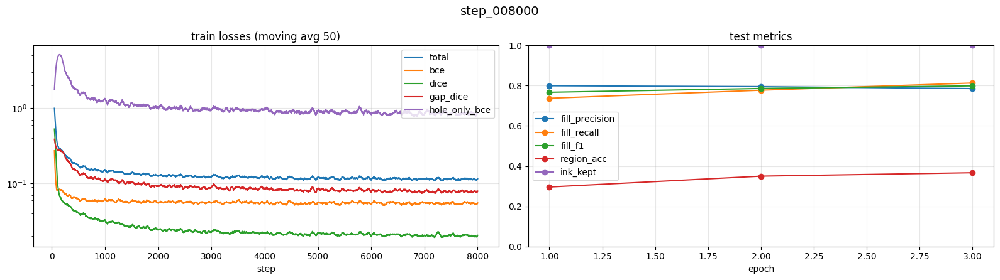

Epoch [4/30] Step [1250/2250] total=0.1121 bce=0.0512 dice=0.0213 hole_only=0.7242 hole_frac=0.0028
Epoch [4/30] Step [1260/2250] total=0.1048 bce=0.0439 dice=0.0196 hole_only=0.9110 hole_frac=0.0018
Epoch [4/30] Step [1270/2250] total=0.1151 bce=0.0566 dice=0.0189 hole_only=0.9033 hole_frac=0.0028
Epoch [4/30] Step [1280/2250] total=0.1118 bce=0.0540 dice=0.0199 hole_only=0.8798 hole_frac=0.0022
Epoch [4/30] Step [1290/2250] total=0.1286 bce=0.0633 dice=0.0230 hole_only=0.8632 hole_frac=0.0021
Epoch [4/30] Step [1300/2250] total=0.1044 bce=0.0497 dice=0.0201 hole_only=0.5573 hole_frac=0.0024
Epoch [4/30] Step [1310/2250] total=0.1237 bce=0.0564 dice=0.0216 hole_only=1.1411 hole_frac=0.0020
Epoch [4/30] Step [1320/2250] total=0.1120 bce=0.0530 dice=0.0199 hole_only=0.9118 hole_frac=0.0021
Epoch [4/30] Step [1330/2250] total=0.1534 bce=0.0770 dice=0.0244 hole_only=1.1469 hole_frac=0.0019
Epoch [4/30] Step [1340/2250] total=0.1428 bce=0.0702 dice=0.0221 hole_only=1.3009 hole_frac=0.0018


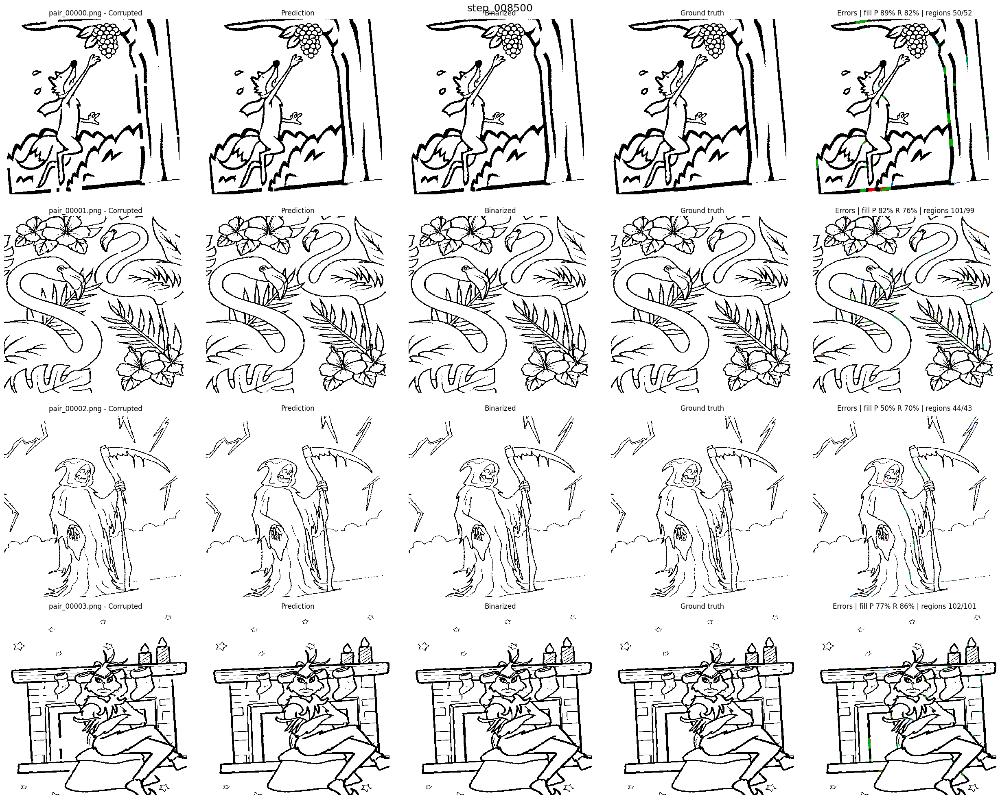

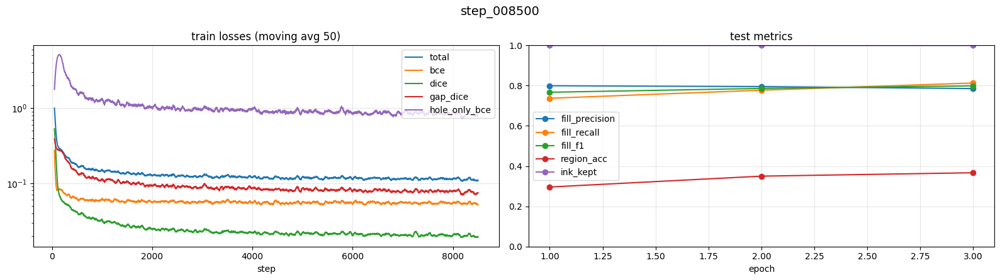

Epoch [4/30] Step [1750/2250] total=0.0960 bce=0.0437 dice=0.0165 hole_only=0.6444 hole_frac=0.0025
Epoch [4/30] Step [1760/2250] total=0.1256 bce=0.0540 dice=0.0224 hole_only=0.9815 hole_frac=0.0018
Epoch [4/30] Step [1770/2250] total=0.1149 bce=0.0479 dice=0.0191 hole_only=1.1822 hole_frac=0.0018
Epoch [4/30] Step [1780/2250] total=0.1265 bce=0.0441 dice=0.0276 hole_only=0.9370 hole_frac=0.0032
Epoch [4/30] Step [1790/2250] total=0.1011 bce=0.0521 dice=0.0182 hole_only=0.4530 hole_frac=0.0033
Epoch [4/30] Step [1800/2250] total=0.1058 bce=0.0432 dice=0.0192 hole_only=0.8730 hole_frac=0.0024
Epoch [4/30] Step [1810/2250] total=0.0824 bce=0.0390 dice=0.0145 hole_only=0.5102 hole_frac=0.0030
Epoch [4/30] Step [1820/2250] total=0.1406 bce=0.0724 dice=0.0250 hole_only=1.0877 hole_frac=0.0019
Epoch [4/30] Step [1830/2250] total=0.0915 bce=0.0422 dice=0.0156 hole_only=0.6672 hole_frac=0.0030
Epoch [4/30] Step [1840/2250] total=0.1101 bce=0.0509 dice=0.0206 hole_only=0.9751 hole_frac=0.0019


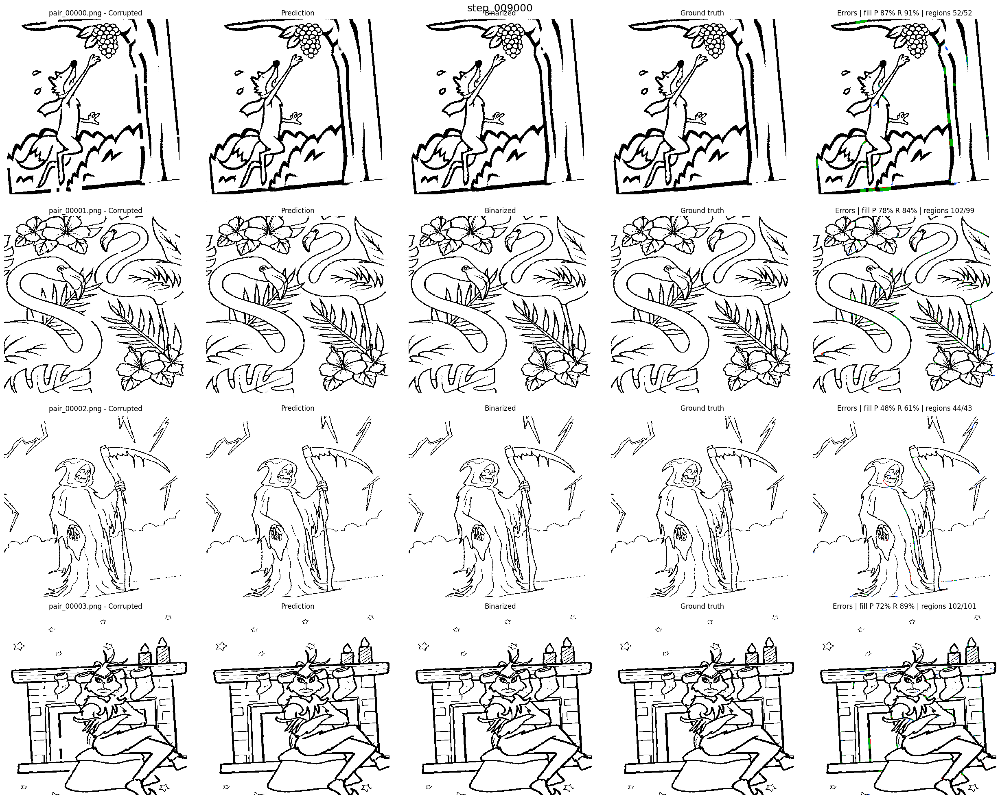

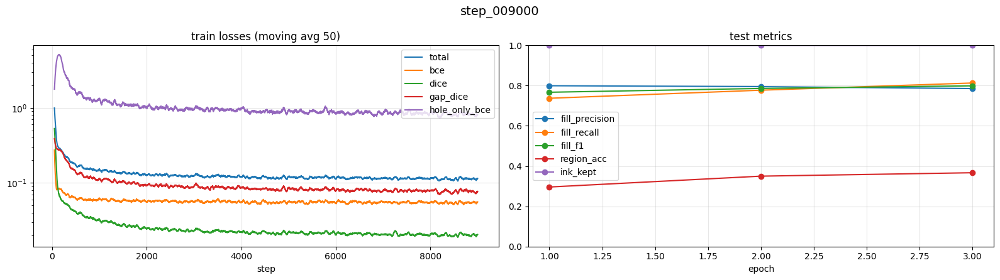

Epoch [4/30]
  TEST fill_precision=0.7568 fill_recall=0.8439 fill_f1=0.7980 ink_kept=1.0000 px_f1=0.9932 ink_ratio=1.0036 region_acc=0.3670 region_recovery=0.9536 regions_pred=53.4560 regions_gt=53.4250


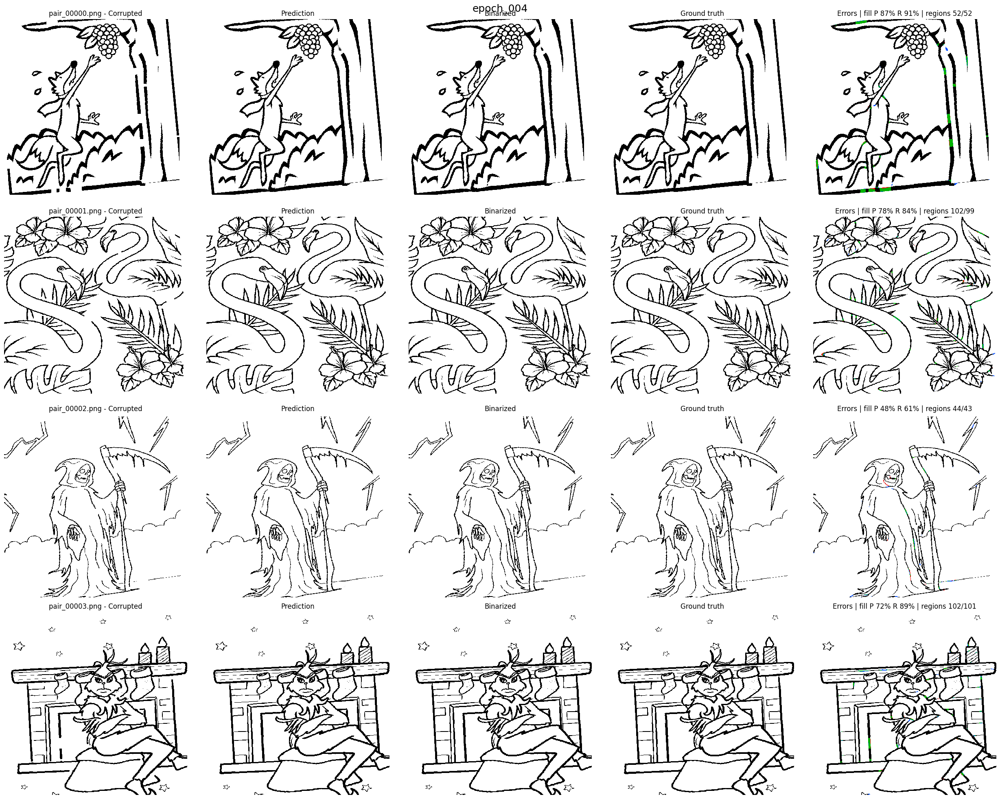

Epoch [5/30] Step [0/2250] total=0.1249 bce=0.0578 dice=0.0244 hole_only=1.0139 hole_frac=0.0025
Epoch [5/30] Step [10/2250] total=0.1320 bce=0.0623 dice=0.0226 hole_only=1.1315 hole_frac=0.0021
Epoch [5/30] Step [20/2250] total=0.1317 bce=0.0558 dice=0.0230 hole_only=1.2069 hole_frac=0.0023
Epoch [5/30] Step [30/2250] total=0.1496 bce=0.0758 dice=0.0272 hole_only=1.2440 hole_frac=0.0015
Epoch [5/30] Step [40/2250] total=0.1199 bce=0.0565 dice=0.0194 hole_only=0.8779 hole_frac=0.0017
Epoch [5/30] Step [50/2250] total=0.1008 bce=0.0567 dice=0.0191 hole_only=0.5525 hole_frac=0.0031
Epoch [5/30] Step [60/2250] total=0.1014 bce=0.0497 dice=0.0179 hole_only=0.9932 hole_frac=0.0033
Epoch [5/30] Step [70/2250] total=0.1152 bce=0.0593 dice=0.0211 hole_only=0.9093 hole_frac=0.0014
Epoch [5/30] Step [80/2250] total=0.0871 bce=0.0427 dice=0.0160 hole_only=0.5196 hole_frac=0.0032
Epoch [5/30] Step [90/2250] total=0.1107 bce=0.0555 dice=0.0214 hole_only=0.5207 hole_frac=0.0031
Epoch [5/30] Step [10

KeyboardInterrupt: 

In [ ]:
# CODE BLOCK 13 (TRAIN)

import torch.nn.functional as F
from torch.amp import autocast, GradScaler

train_losses, history = [], []
loss_log = {k: [] for k in LOSS_KEYS}
epoch_losses = []
prev_epoch_loss = None

PREVIEW_EVERY = 500
global_step   = 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

#Initialize model!
model = LineInpainter().to(device)

epochs = 30

#optimizer = torch.optim.AdamW([
#    {'params': list(model.encoder.parameters()) + list(model.decoder.parameters()), 'lr': 1e-3},
#    {'params': model.bottleneck_attn.parameters(), 'lr': 3e-4},
#    {'params': model.mid_attn.parameters(), 'lr': 3e-4},
#], weight_decay=1e-4)

attn_params = list(model.bottleneck_attn.parameters()) + list(model.mid_attn.parameters())
attn_ids    = {id(p) for p in attn_params}
conv_params = [p for p in model.parameters() if id(p) not in attn_ids]

optimizer = torch.optim.AdamW([
    {'params': conv_params, 'lr': 1e-3},
    {'params': attn_params, 'lr': 3e-4},
], weight_decay=1e-4)

n_opt = sum(p.numel() for g in optimizer.param_groups for p in g['params'])
assert n_opt == sum(p.numel() for p in model.parameters()), "params missing from optimizer"

#Add cosine LR scheduling
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=epochs, eta_min=1e-6
)
scaler = GradScaler('cuda')

#LOSS FUNCTION

criterion = LineLoss(
    hole_weight=3.0,    # was 8 — much milder, Dice handles imbalance better
    bce_weight=1.0,
    dice_weight=1.0,
).to(device)

# Initialize loss tracking lists
train_losses = []
epoch_losses = []
prev_epoch_loss = None

for epoch in range(epochs):

    model.train()
    epoch_loss = 0
    batch_losses = []  # Track loss for each batch

    for i, (corrupted, clean) in enumerate(train_loader):
        corrupted, clean = corrupted.to(device), clean.to(device)
        #To reduce memory
        '''
        output = model(corrupted)
        loss = criterion(output, clean, corrupted)
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        '''
        #Replaced with
        optimizer.zero_grad()
        #with autocast('cuda', dtype=torch.float16):
        #    output = model(corrupted)
        #    loss = criterion(output, clean, corrupted)
        with autocast('cuda', dtype=torch.float16):
            output = model(corrupted)
        loss = criterion(output.float(), clean, corrupted)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        ######

        # Track losses
        batch_loss = loss.item()
        epoch_loss += batch_loss
        batch_losses.append(batch_loss)
        train_losses.append(batch_loss)  # Store every batch loss
        global_step += 1
        for k in LOSS_KEYS:                                   # NEW
            loss_log[k].append(criterion.last_components[k])  # NEW
        '''
        if i % 10 == 0:
          c = criterion.last_components
          print(f"Epoch [{epoch+1}/{epochs}] Step [{i}/{len(dataloader)}] "
                f"total={c['total']:.4f} bce={c['bce']:.4f} dice={c['dice']:.4f} "
                f"sobel={c['sobel']:.4f} hole={c['hole_recon']:.4f} "
                f"hole_frac={c['hole_fraction']:.4f}")
        '''
        # Logging
        if i % 10 == 0:
            c = criterion.last_components
            print(
                f"Epoch [{epoch+1}/{epochs}] Step [{i}/{len(train_loader)}] "
                f"total={c['total']:.4f} bce={c['bce']:.4f} dice={c['dice']:.4f} "
                f"hole_only={c['hole_only_bce']:.4f} hole_frac={c['hole_frac']:.4f}"
            )
       # ---- periodic preview ----
        if global_step % PREVIEW_EVERY == 0:
            show_predictions(model, ex_corrupted, ex_clean, f"step_{global_step:06d}")
            plot_curves(loss_log, history, f"step_{global_step:06d}")   # NEW
    print(f"Epoch [{epoch+1}/{epochs}]")
    lr_groups = [pg['lr'] for pg in optimizer.param_groups]

    m = evaluate(model, test_loader)
    history.append(m)                                         # NEW
    print("  TEST " + " ".join(f"{k}={v:.4f}" for k, v in m.items()))
    show_predictions(model, ex_corrupted, ex_clean, f"epoch_{epoch+1:03d}")

    scheduler.step()

print("Done!")

# **SAVE CHECKPONT**

In [ ]:
# SAVE CHECKPOINT TO LOCAL DISK
import os, torch
from google.colab import files

os.makedirs("/content/checkpoints", exist_ok=True)
epochs_done = len(history)          # one entry per finished epoch (evaluate runs at epoch end)
path = f"/content/checkpoints/inkrepair_ep{epochs_done:03d}.pt"

torch.save(dict(
    model       = model.state_dict(),
    optimizer   = optimizer.state_dict(),   # Adam moments: needed to resume smoothly
    scheduler   = scheduler.state_dict(),   # where the cosine LR schedule is
    scaler      = scaler.state_dict(),      # fp16 loss scale
    history     = history,                  # test metrics per epoch
    loss_log    = loss_log,                 # per-step losses for the curves
    global_step = global_step,
    epochs_done = epochs_done,
), path)

print(f"{path}: {os.path.getsize(path) / 1e6:.0f} MB")
files.download(path)

/content/checkpoints/inkrepair_ep004.pt: 526 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# ***TEST SAMPLES***

In [ ]:
# TEST ON THE SAMPLE IMAGES

import numpy as np
import torch

model.eval()
with torch.no_grad():
    with autocast('cuda', dtype=torch.float16):
        pred = model(ex_corrupted.to(device))      # eval branch -> probabilities
    pred = pred.float().cpu()

binar = (pred > 0.5).float()

print(f"{'image':28s} {'gap filled':>11s} {'ink kept':>9s} {'ink ratio':>10s}")
for r in range(len(EXAMPLE_FILES)):
    c = ex_corrupted[r, 0].numpy()
    g = ex_clean[r, 0].numpy()
    b = binar[r, 0].numpy()

    c_ink, g_ink, p_ink = c < 0.5, g < 0.5, b < 0.5
    gap = g_ink & ~c_ink

    fill_recall = (p_ink & gap).sum() / max(gap.sum(), 1)   # holes closed
    ink_kept    = (p_ink & c_ink).sum() / max(c_ink.sum(), 1)  # input ink preserved
    ink_ratio   = p_ink.sum() / max(g_ink.sum(), 1)          # thickness watchdog

    print(f"{EXAMPLE_FILES[r]:28s} {fill_recall:10.1%} {ink_kept:8.1%} {ink_ratio:9.2f}")

# the 5-panel view: corrupted / prediction / binarized / GT / error map
show_predictions(model, ex_corrupted, ex_clean, "manual_check")

model.train()   # leave the model ready for more training

# **TEST**

In [ ]:
if len(train_losses) > 0:
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    axes[0].plot(train_losses, alpha=0.6, linewidth=0.5)
    axes[0].set_xlabel('Batch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training Loss per Batch')
    axes[0].grid(True, alpha=0.3)

    # epoch_losses is empty — use prev_epoch_loss history instead
    # prev_epoch_loss tracks the last epoch avg, so rebuild from print_epoch_summary return values
    # The simplest fix: recompute epoch avgs from batch losses and dataloader size
    batches_per_epoch = len(dataloader)
    num_complete_epochs = len(train_losses) // batches_per_epoch
    epoch_avgs = [
        sum(train_losses[i*batches_per_epoch:(i+1)*batches_per_epoch]) / batches_per_epoch
        for i in range(num_complete_epochs)
    ]

    if len(epoch_avgs) > 0:
        axes[1].plot(range(1, len(epoch_avgs)+1), epoch_avgs, marker='o', linewidth=2, markersize=8)
        axes[1].set_xlabel('Epoch')
        axes[1].set_ylabel('Average Loss')
        axes[1].set_title('Average Training Loss per Epoch')
        axes[1].grid(True, alpha=0.3)
    else:
        axes[1].text(0.5, 0.5, 'No complete epochs yet',
                     ha='center', va='center', transform=axes[1].transAxes)
        axes[1].set_title('Average Training Loss per Epoch')

    plt.tight_layout()
    plt.savefig('training_loss.png', dpi=150, bbox_inches='tight')
    plt.show()

    print("\n=== Training Summary ===")
    print(f"Total batches trained: {len(train_losses)}")
    print(f"Epochs completed: {num_complete_epochs}")
    print(f"Initial loss: {train_losses[0]:.4f}")
    print(f"Final loss: {train_losses[-1]:.4f}")
    if len(epoch_avgs) > 0:
        best_epoch = epoch_avgs.index(min(epoch_avgs)) + 1
        print(f"Best epoch loss: {min(epoch_avgs):.4f} (Epoch {best_epoch})")
    print(f"Loss reduction: {((train_losses[0] - train_losses[-1]) / train_losses[0] * 100):.2f}%")
else:
    print("No training data to plot!")

In [ ]:
# Visualization if output one channel (SELECT CORRUPTION LEVEL 3)

#setCorruptionLevel(level=3)
model.eval()
with torch.no_grad():
    corrupted, clean = next(iter(dataloader))
    corrupted, clean = corrupted.to(device), clean.to(device)

    output = model(corrupted)


    bin_output = (output > 0.5).float()

    fig, axes = plt.subplots(4, 2, figsize=(100, 100))

    for i in range(2):
        # All images are now (1, H, W), squeeze to (H, W) for display
        axes[0, i].imshow(corrupted[i, 0].cpu(), cmap='gray')
        axes[0, i].set_title('Corrupted')
        axes[0, i].axis('off')

        axes[1, i].imshow(output[i, 0].cpu(), cmap='gray')
        axes[1, i].set_title('Reconstructed')
        axes[1, i].axis('off')

        axes[2, i].imshow(clean[i, 0].cpu(), cmap='gray')
        axes[2, i].set_title('Ground Truth')
        axes[2, i].axis('off')

        axes[3, i].imshow(bin_output[i, 0].cpu(), cmap='gray')
        axes[3, i].set_title('Binarized')
        axes[3, i].axis('off')

    plt.tight_layout()
    plt.show()

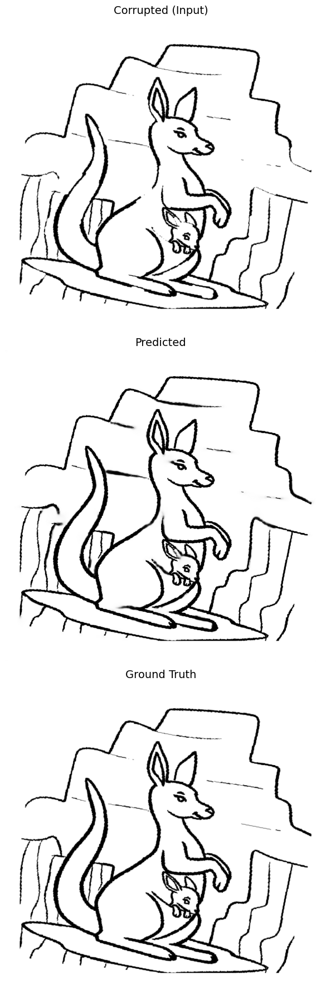

In [ ]:
import matplotlib.pyplot as plt

# Get one batch
model.eval()
with torch.no_grad():
    corrupted, clean = next(iter(dataloader))
    corrupted, clean = corrupted.to(device), clean.to(device)
    predicted = model(corrupted)

# Take first image from batch
corrupted_img = corrupted[0, 0].cpu().numpy()
clean_img = clean[0, 0].cpu().numpy()
predicted_img = predicted[0, 0].cpu().numpy()

# Plot as column
fig, axes = plt.subplots(3, 1, figsize=(8, 18))

axes[0].imshow(corrupted_img, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Corrupted (Input)', fontsize=14)
axes[0].axis('off')

axes[1].imshow(predicted_img, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Predicted', fontsize=14)
axes[1].axis('off')

axes[2].imshow(clean_img, cmap='gray', vmin=0, vmax=1)
axes[2].set_title('Ground Truth', fontsize=14)
axes[2].axis('off')

plt.tight_layout()
plt.show()

CHECK FILE FROM LINEARTANIM

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving 001.png to 001.png


In [ ]:
!ls

001.png  checkpoints  dataset  dataset.zip  sample_data  training_loss.png


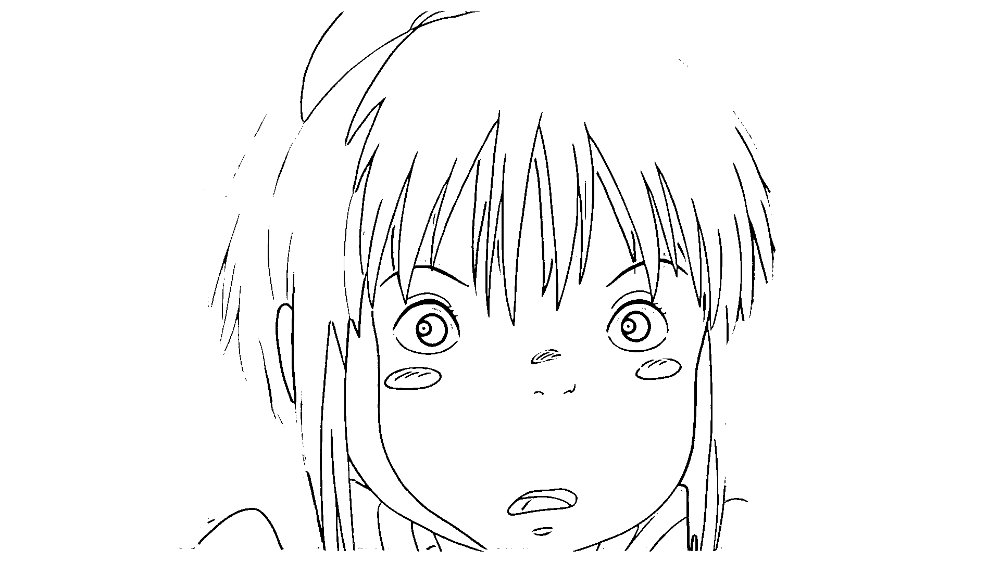

In [ ]:
from PIL import Image

img = Image.open('001.png')
display(img)

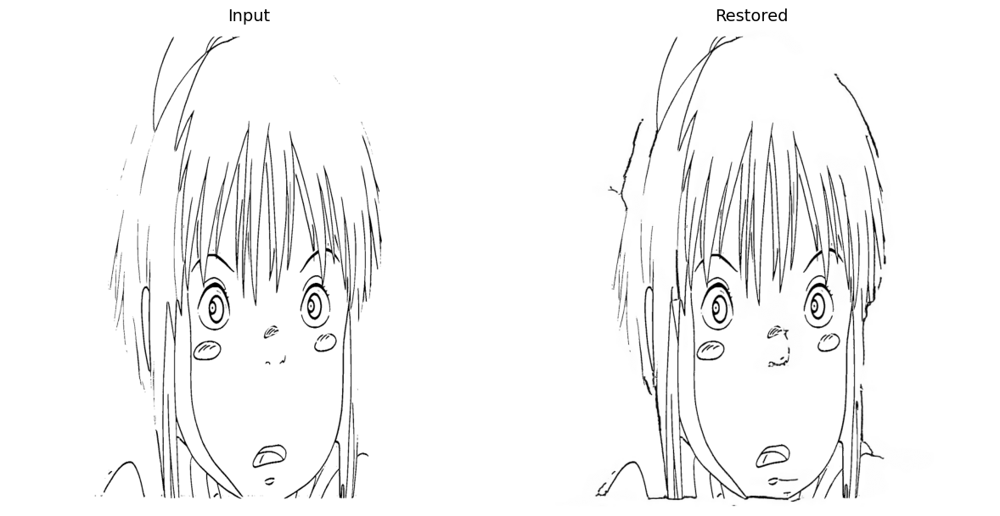

In [ ]:
from PIL import Image
import torch
import numpy as np
import matplotlib.pyplot as plt

# Load and preprocess the image
img = Image.open("001.png").convert('L')  # Convert to grayscale
img = img.resize((896, 896))  # Adjust to your model's expected input size

# Convert to tensor and normalize to [0, 1]
img_tensor = torch.from_numpy(np.array(img)).float() / 255.0
img_tensor = img_tensor.unsqueeze(0).unsqueeze(0)  # Add batch and channel dims: (1, 1, H, W)
img_tensor = img_tensor.to(device)

# Run inference
model.eval()
with torch.no_grad():
    predicted = model(img_tensor)

# Convert back to numpy for visualization
input_img = img_tensor[0, 0].cpu().numpy()
predicted_img = predicted[0, 0].cpu().numpy()

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(input_img, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Input', fontsize=14)
axes[0].axis('off')

axes[1].imshow(predicted_img, cmap='gray', vmin=0, vmax=1)
axes[1].set_title('Restored', fontsize=14)
axes[1].axis('off')

plt.tight_layout()
plt.show()